In [1]:
import sys
print(sys.executable)


c:\Users\Neha\anaconda3\python.exe


In [2]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Joblib:", joblib.__version__)

print("\nALL PACKAGES WORKING ✅")

NumPy: 2.3.5
Pandas: 2.3.3
Matplotlib: 3.10.6
Seaborn: 0.13.2
Scikit-learn: 1.7.2
Joblib: 1.5.2

ALL PACKAGES WORKING ✅


In [3]:
df = pd.read_csv("C:/Users/Neha/Downloads/fer2013.csv")
df.head()

,emotion,pixels,Usage
0,0,70 80 82 72 58 58 60 63 54 58 60 48 89 115 121...,Training
1,0,151 150 147 155 148 133 111 140 170 174 182 15...,Training
2,2,231 212 156 164 174 138 161 173 182 200 106 38...,Training
3,4,24 32 36 30 32 23 19 20 30 41 21 22 32 34 21 1...,Training
4,6,4 0 0 0 0 0 0 0 0 0 0 0 3 15 23 28 48 50 58 84...,Training


In [4]:
print("Dataset Shape:", df.shape)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (35887, 3)
Number of Rows: 35887
Number of Columns: 3


In [5]:
print("Data Types:")
print(df.dtypes)

Data Types:
emotion     int64
pixels     object
Usage      object
dtype: object


In [6]:
print(df.isnull().sum())

emotion    0
pixels     0
Usage      0
dtype: int64


Observation: The distribution of mean pixel intensity shows how overall brightness varies across the facial images. Most images are concentrated within a particular intensity range, while relatively few images have very low or very high average brightness.

In [7]:
# 1. Convert the entire column of space-separated strings into a 2D NumPy array efficiently
pixel_matrix = np.vstack(
    df["pixels"].apply(lambda x: np.fromstring(x, sep=" ", dtype=np.uint8)).values
)

# 2. Calculate the statistical features directly across the columns (axis=1)
df["pixel_mean"] = pixel_matrix.mean(axis=1)
df["pixel_std"] = pixel_matrix.std(axis=1)
df["pixel_min"] = pixel_matrix.min(axis=1)
df["pixel_max"] = pixel_matrix.max(axis=1)


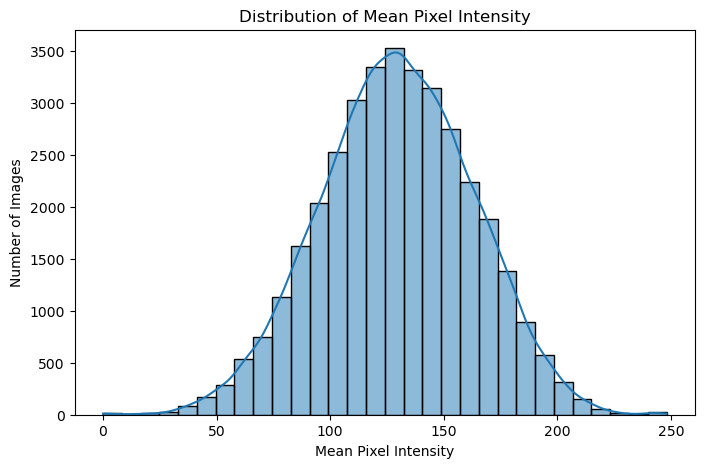

In [8]:
plt.figure(figsize=(8, 5))

sns.histplot(df["pixel_mean"], bins=30, kde=True)

plt.title("Distribution of Mean Pixel Intensity")
plt.xlabel("Mean Pixel Intensity")
plt.ylabel("Number of Images")

plt.show()

Observation: Pixel standard deviation represents the variation in intensity within an image. Higher values indicate greater contrast or variation between darker and brighter regions of the face.

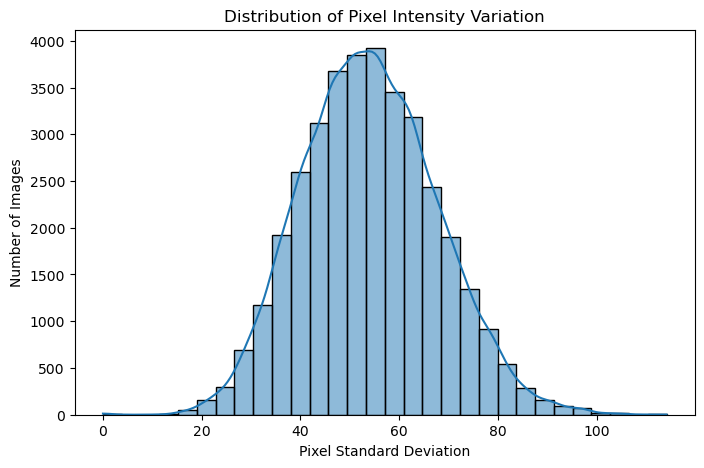

In [9]:
plt.figure(figsize=(8, 5))

sns.histplot(df["pixel_std"], bins=30, kde=True)

plt.title("Distribution of Pixel Intensity Variation")
plt.xlabel("Pixel Standard Deviation")
plt.ylabel("Number of Images")

plt.show()

Observation: The emotion classes are not perfectly balanced. Some emotions contain considerably more samples than others. Therefore, accuracy alone may not fully represent model performance, and weighted F1-score will also be used for evaluation.

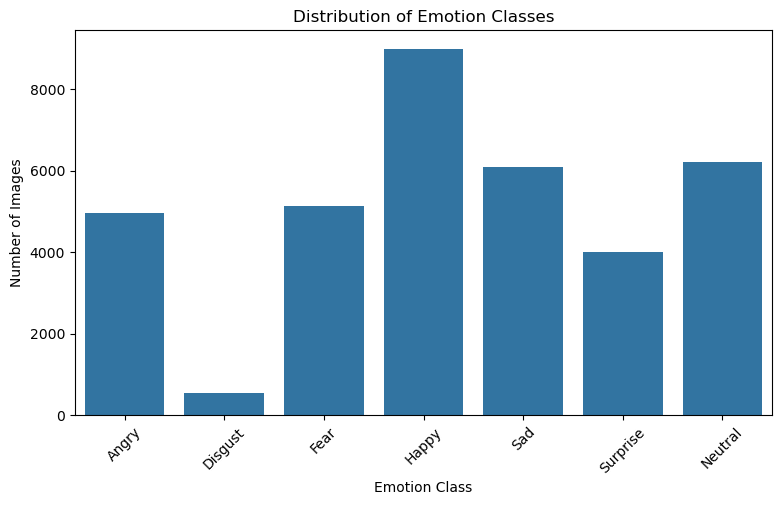

In [10]:
emotion_names = {
    0: "Angry",
    1: "Disgust",
    2: "Fear",
    3: "Happy",
    4: "Sad",
    5: "Surprise",
    6: "Neutral"
}

plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="emotion")

plt.title("Distribution of Emotion Classes")
plt.xlabel("Emotion Class")
plt.ylabel("Number of Images")
plt.xticks(
    ticks=range(7),
    labels=[emotion_names[i] for i in range(7)],
    rotation=45
)

plt.show()

Observation: The sample images show visible differences in facial expressions across the seven emotion classes. For example, happy images generally show smiling expressions, while angry and sad images have different facial configurations. However, some expressions can appear visually similar, which makes emotion classification a challenging task.

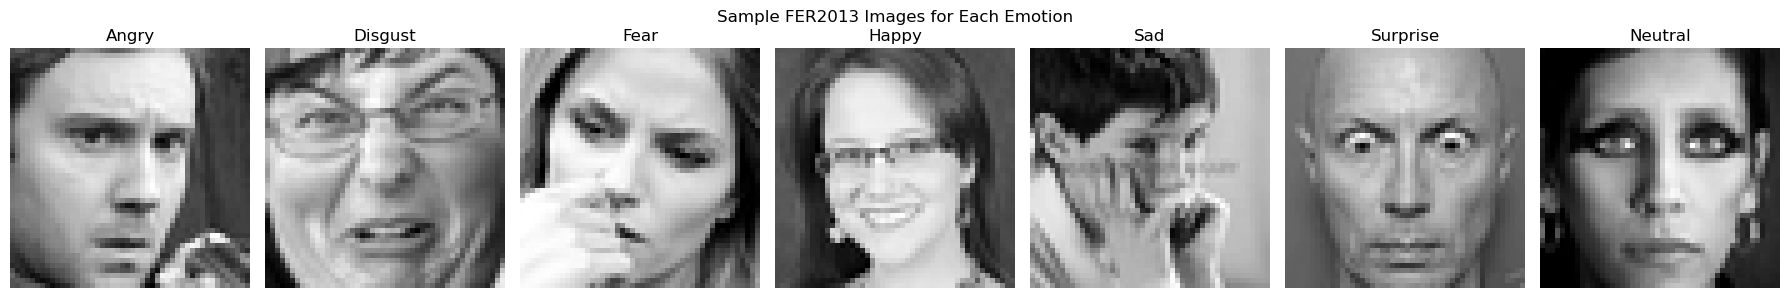

In [11]:
# Display one image from each emotion class

fig, axes = plt.subplots(1, 7, figsize=(18, 3))

for emotion_id in range(7):
    # Get the first image belonging to this emotion
    row = df[df["emotion"] == emotion_id].iloc[0]

    # Convert pixel string into a 48x48 image
    image = np.array(row["pixels"].split(), dtype=np.uint8).reshape(48, 48)

    axes[emotion_id].imshow(image, cmap="gray")
    axes[emotion_id].set_title(emotion_names[emotion_id])
    axes[emotion_id].axis("off")

plt.suptitle("Sample FER2013 Images for Each Emotion")
plt.tight_layout()
plt.show()

Observation: The correlation heatmap shows the relationships among the emotion label and the extracted pixel-statistical features. The pixel statistics also show relationships with one another because they are calculated from the same image intensity values. The correlations with the emotion label are relatively limited, indicating that simple pixel statistics alone may not be sufficient to distinguish all facial expressions.

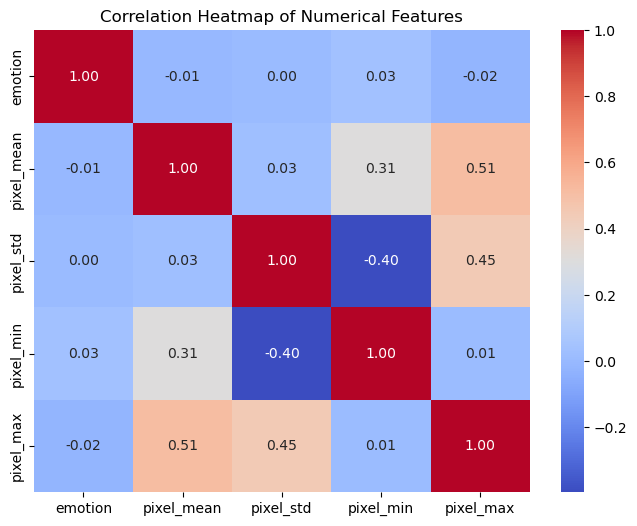

In [12]:
# Correlation heatmap

correlation_data = df[
    ["emotion", "pixel_mean", "pixel_std", "pixel_min", "pixel_max"]
]

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_data.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

Observation: The boxplot shows how the average brightness of facial images varies across emotion classes. Some emotions have slightly different median pixel intensities, but there is considerable overlap between classes. This suggests that mean brightness alone is not enough to reliably separate the emotions.

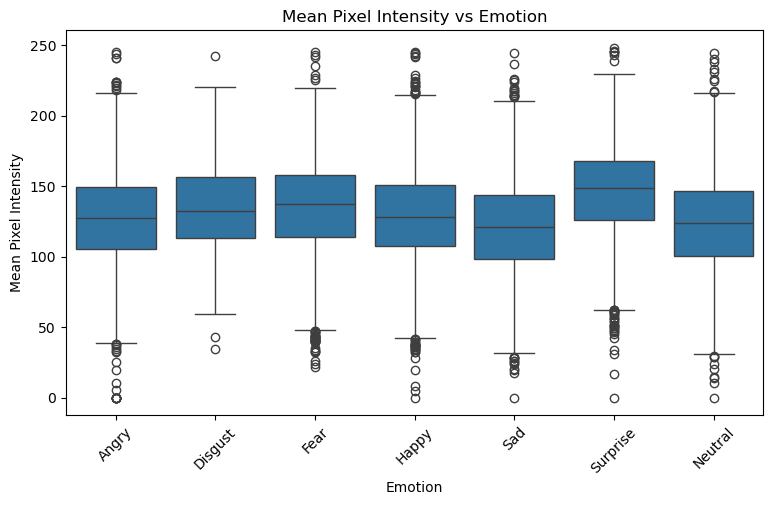

In [13]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="emotion",
    y="pixel_mean"
)

plt.title("Mean Pixel Intensity vs Emotion")
plt.xlabel("Emotion")
plt.ylabel("Mean Pixel Intensity")
plt.xticks(
    ticks=range(7),
    labels=[emotion_names[i] for i in range(7)],
    rotation=45
)

plt.show()

Observation: The plot shows the variation in pixel intensity for different emotion classes. Although some classes have different distributions of pixel variation, there is substantial overlap among the classes. Therefore, more informative image features or the complete pixel representation are required for effective emotion classification.

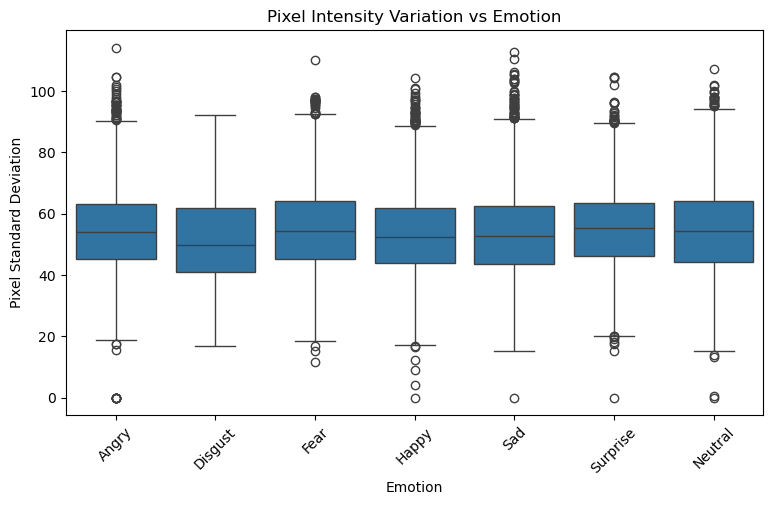

In [14]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="emotion",
    y="pixel_std"
)

plt.title("Pixel Intensity Variation vs Emotion")
plt.xlabel("Emotion")
plt.ylabel("Pixel Standard Deviation")
plt.xticks(
    ticks=range(7),
    labels=[emotion_names[i] for i in range(7)],
    rotation=45
)

plt.show()

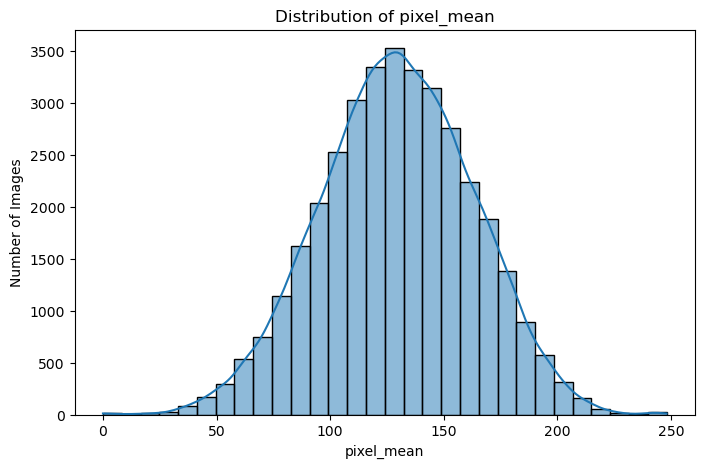

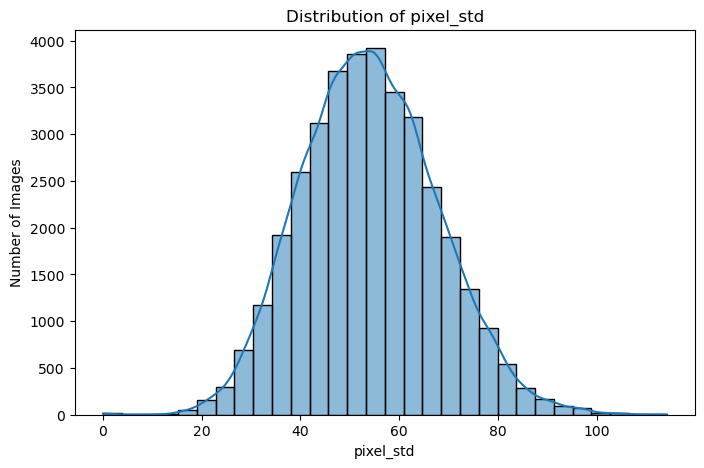

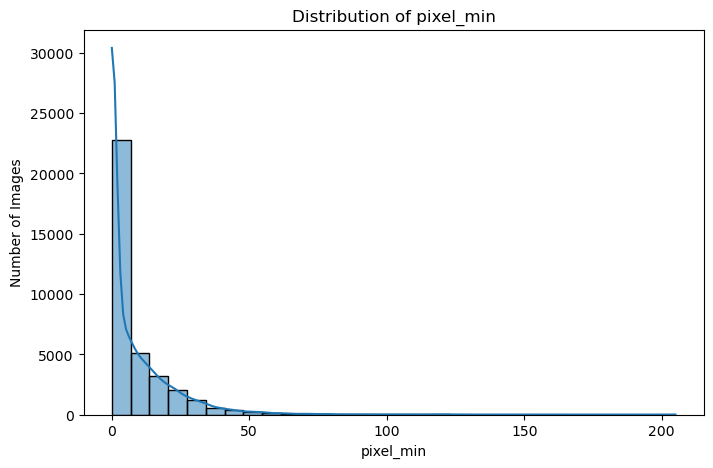

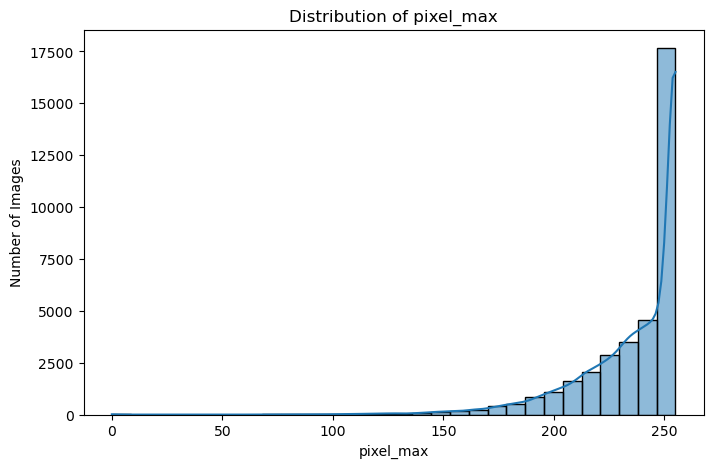

In [15]:
features = ["pixel_mean", "pixel_std", "pixel_min", "pixel_max"]

for feature in features:
    plt.figure(figsize=(8, 5))

    sns.histplot(
        df[feature],
        bins=30,
        kde=True
    )

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Number of Images")

    plt.show()

B1

Missing Value Treatment: No missing values were found in the dataset. Therefore, no imputation or row removal was necessary.

In [16]:
missing_values = df.isnull().sum()

print("Missing values before treatment:")
print(missing_values)

if missing_values.sum() == 0:
    print("\nNo missing values found. No imputation is required.")
else:
    df = df.dropna()
    print("\nMissing rows were removed.")

Missing values before treatment:
emotion       0
pixels        0
Usage         0
pixel_mean    0
pixel_std     0
pixel_min     0
pixel_max     0
dtype: int64

No missing values found. No imputation is required.


Duplicate Treatment: The dataset contained 1,234 exact duplicate rows. These rows were removed using drop_duplicates() to prevent identical observations from receiving additional weight during model training.

In [17]:
duplicates_before = df.duplicated().sum()

print("Duplicate rows before treatment:", duplicates_before)

df = df.drop_duplicates()

duplicates_after = df.duplicated().sum()

print("Duplicate rows after treatment:", duplicates_after)
print("Dataset shape after removing duplicates:", df.shape)

Duplicate rows before treatment: 1234
Duplicate rows after treatment: 0
Dataset shape after removing duplicates: (34653, 7)


Outlier Treatment: Pixel values were first checked for invalid values outside the permissible 0–255 grayscale range. Statistical outliers in image-level pixel statistics were also examined using the IQR method. Extreme pixel statistics were retained when they represented valid facial images rather than erroneous observations.

In [18]:
# ==========================================================
# 0. Efficiently Parse Data to Avoid Memory Errors
# ==========================================================
print("Parsing pixel data efficiently...")

# Convert space-separated strings directly to a fast 2D NumPy matrix
# We use float32 temporarily to safely catch any malformed numbers if present
pixel_matrix = np.vstack(
    df["pixels"].apply(lambda x: np.fromstring(x, sep=" ", dtype=np.float32)).values
)


# ==========================================================
# 1. Check for invalid pixel values
# ==========================================================
# Look across columns (axis=1) to see which rows violate the 0-255 boundary rules
invalid_rows_mask = np.any((pixel_matrix < 0) | (pixel_matrix > 255), axis=1)

print("Rows containing invalid pixel values:", invalid_rows_mask.sum())


# ==========================================================
# 3. Treat invalid pixel values (Moved up to clean matrix first)
# ==========================================================
if invalid_rows_mask.sum() == 0:
    print("No invalid pixel values found.")
else:
    # Filter both our original DataFrame and our working NumPy matrix
    df = df[~invalid_rows_mask].reset_index(drop=True)
    pixel_matrix = pixel_matrix[~invalid_rows_mask]
    print("Rows with invalid pixel values were removed.")


# Downcast matrix to uint8 now that we know values are strictly between 0 and 255
# This dramatically minimizes RAM usage going forward
pixel_matrix = pixel_matrix.astype(np.uint8)


# ==========================================================
# 2. Statistical outlier detection using IQR
# ==========================================================
# Calculate the pixel means quickly in native NumPy
df["pixel_mean"] = pixel_matrix.mean(axis=1)

Q1 = df["pixel_mean"].quantile(0.25)
Q3 = df["pixel_mean"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df["pixel_mean"] < lower) | (df["pixel_mean"] > upper)]
print("Pixel mean statistical outliers:", len(outliers))


print("Final dataset shape:", df.shape)

Parsing pixel data efficiently...
Rows containing invalid pixel values: 0
No invalid pixel values found.
Pixel mean statistical outliers: 141
Final dataset shape: (34653, 7)


Observation: The data was split into 80% training and 20% testing using stratified sampling. Pixel values were normalized from 0–255 to 0–1.

Create X and y

In [19]:
# Input features (Using np.fromstring completely avoids the memory-heavy text splitting)
X = np.vstack(
    df["pixels"].apply(lambda x: np.fromstring(x, sep=" ", dtype=np.float32)).values
)

# Target
y = df["emotion"].values

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (34653, 2304)
y shape: (34653,)


Train-Test Split

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data :", X_test.shape)

Training data: (27722, 2304)
Testing data : (6931, 2304)


Scale the pixel values

In [21]:
X_train = X_train / 255.0
X_test = X_test / 255.0

print("Training range:", X_train.min(), "to", X_train.max())
print("Testing range :", X_test.min(), "to", X_test.max())

Training range: 0.0 to 1.0
Testing range : 0.0 to 1.0


Observation: Four numerical features were engineered from the pixel data to represent image brightness and intensity variation.

In [22]:
# Calculate the statistical features directly across the columns (axis=1) of your X matrix
df["pixel_mean"] = X.mean(axis=1)
df["pixel_std"] = X.std(axis=1)
df["pixel_min"] = X.min(axis=1)
df["pixel_max"] = X.max(axis=1)

# Display the first few rows of the generated features
df[["pixel_mean", "pixel_std", "pixel_min", "pixel_max"]].head()


,pixel_mean,pixel_std,pixel_min,pixel_max
0,117.592880,50.735355,11.0,210.0
1,126.971352,40.854366,0.0,219.0
2,160.814240,74.711746,0.0,255.0
3,130.503479,59.357460,12.0,235.0
4,97.900177,70.166313,0.0,241.0


Justification: These features provide useful information about the brightness and contrast of facial images and can help analyze differences between emotion classes.

 Logistic Regression

In [23]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

# Reduce 2304 pixels to 100 features
pca = PCA(n_components=100, random_state=42)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("Original features:", X_train.shape[1])
print("Reduced features :", X_train_pca.shape[1])

# Logistic Regression
logistic_model = LogisticRegression(
    solver="lbfgs",
    max_iter=200,
    random_state=42
)

logistic_model.fit(X_train_pca, y_train)

y_pred_lr = logistic_model.predict(X_test_pca)

print("Logistic Regression training completed!")
print("Predictions:", y_pred_lr[:10])

Original features: 2304
Reduced features : 100
Logistic Regression training completed!
Predictions: [5 3 4 4 3 6 2 4 3 3]


In [24]:
# Get Logistic Regression coefficients

lr_coefficients = logistic_model.coef_

print("Coefficient shape:", lr_coefficients.shape)

Coefficient shape: (7, 100)


In [25]:
import numpy as np

for i, emotion in enumerate(emotion_names):

    # Get absolute coefficient values
    coefficient_strength = np.abs(lr_coefficients[i])

    # Find top 5 components
    top_components = np.argsort(
        coefficient_strength
    )[-5:][::-1]

    print("\n", emotion)
    print("Top PCA components:", top_components + 1)
    print("Coefficients:",
          lr_coefficients[i][top_components])


 0
Top PCA components: [65 83 47 51 76]
Coefficients: [ 0.21515322 -0.18098922 -0.1682659   0.15100214  0.1490173 ]

 1
Top PCA components: [ 93  78  67 100  95]
Coefficients: [-0.47130698 -0.46565101 -0.43398805  0.41059472 -0.38788768]

 2
Top PCA components: [46 63 50 28 23]
Coefficients: [ 0.14133579 -0.14083958  0.13613689 -0.13607237 -0.13377285]

 3
Top PCA components: [23 49 65 51 67]
Coefficients: [ 0.53278044 -0.30767375 -0.28636242 -0.28271036  0.28157364]

 4
Top PCA components: [30 17 51 49 19]
Coefficients: [-0.21341416 -0.16615977  0.12513995  0.10758952 -0.10634326]

 5
Top PCA components: [14 36 33 23 93]
Coefficients: [ 0.44044859 -0.40653271 -0.37903047 -0.35870065  0.35251247]

 6
Top PCA components: [ 98  91  76  22 100]
Coefficients: [-0.23793185  0.23153022 -0.21189994 -0.16844451 -0.16423099]


In [26]:
import numpy as np

happy_coefficient = 0.53278044

odds_ratio = np.exp(happy_coefficient)

print("Odds ratio:", odds_ratio)

Odds ratio: 1.7036626611499535


In [27]:
from sklearn.metrics import accuracy_score, f1_score

# Calculate accuracy
lr_accuracy = accuracy_score(y_test, y_pred_lr)

# Calculate weighted F1-score
lr_f1 = f1_score(y_test, y_pred_lr, average="weighted")

print("Logistic Regression Accuracy:", lr_accuracy)
print("Logistic Regression Weighted F1:", lr_f1)

Logistic Regression Accuracy: 0.36517097099985574
Logistic Regression Weighted F1: 0.3338712836969175


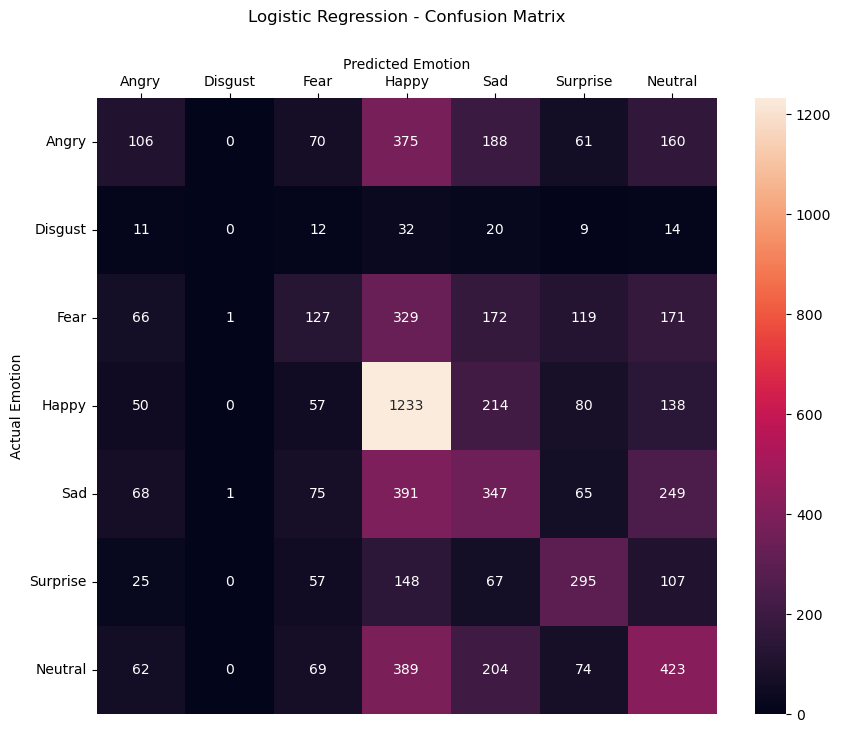

In [28]:
from sklearn.metrics import confusion_matrix

cm_lr = confusion_matrix(y_test, y_pred_lr)

emotion_names = [
    "Angry", "Disgust", "Fear",
    "Happy", "Sad", "Surprise", "Neutral"
]

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    xticklabels=emotion_names,
    yticklabels=emotion_names
)

# Move predicted class names to top
plt.tick_params(
    axis="x",
    top=True,
    labeltop=True,
    bottom=False,
    labelbottom=False
)

plt.xticks(rotation=0)
plt.yticks(rotation=0)

# Put "Predicted Emotion" at the TOP
plt.xlabel("Predicted Emotion")
plt.gca().xaxis.set_label_position("top")
plt.gca().xaxis.label.set_visible(True)

plt.ylabel("Actual Emotion")

plt.title("Logistic Regression - Confusion Matrix", pad=55)

plt.show()

In [29]:
from sklearn.metrics import classification_report

print("Logistic Regression - Classification Report\n")

print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=[
            "Angry",
            "Disgust",
            "Fear",
            "Happy",
            "Sad",
            "Surprise",
            "Neutral"
        ]
    )
)

Logistic Regression - Classification Report

              precision    recall  f1-score   support

       Angry       0.27      0.11      0.16       960
     Disgust       0.00      0.00      0.00        98
        Fear       0.27      0.13      0.17       985
       Happy       0.43      0.70      0.53      1772
         Sad       0.29      0.29      0.29      1196
    Surprise       0.42      0.42      0.42       699
     Neutral       0.34      0.35      0.34      1221

    accuracy                           0.37      6931
   macro avg       0.29      0.28      0.27      6931
weighted avg       0.34      0.37      0.33      6931



### Logistic Regression Coefficient and Odds Interpretation

The Logistic Regression coefficients show how the PCA components influence each emotion class. A positive coefficient increases the tendency toward that emotion, while a negative coefficient decreases it. The magnitude of the coefficient indicates the strength of the influence.

For example, for the Happy class, PC23 has a coefficient of approximately +0.533, indicating a relatively strong positive contribution toward the Happy class. PC49 has a coefficient of approximately -0.308, indicating a negative contribution.

The coefficient of PC23 corresponds to an odds ratio of approximately 1.70 using exp(coefficient). Thus, a one-unit increase in PC23 multiplies the odds of predicting the Happy class by approximately 1.70, while keeping other PCA components constant.

Since PCA was used, these coefficients represent PCA components rather than individual facial pixels.

Train KNN and make predictions

### KNN Distance Metric Discussion

K-Nearest Neighbors (KNN) classifies a new image by finding the training samples that are closest to it.

In this project, KNN uses the default **Minkowski distance with p = 2**, which is equivalent to **Euclidean distance**.

Euclidean distance measures the straight-line distance between two data points. Since the pixel values were normalized before PCA, differences in feature scale are reduced.

Other distance metrics that can be used with KNN include:

- **Euclidean distance (p = 2):** Measures straight-line distance and is commonly used for continuous numerical features.
- **Manhattan distance (p = 1):** Measures the sum of absolute differences between features.
- **Minkowski distance:** A general distance metric where different values of p produce different distance measures.

Euclidean distance was used because the FER2013 data consists of continuous numerical pixel features, and it provides a standard way to measure similarity between images in the PCA feature space.

Since KNN is a distance-based algorithm, feature scaling is important. Therefore, the pixel values were normalized before applying PCA and KNN.

In [30]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import pandas as pd

# Values of k to test
k_values = [3, 5, 7, 9]

knn_results = []

# Try different values of k
for k in k_values:

    print("Training KNN with k =", k)

    # Create KNN model
    knn_model = KNeighborsClassifier(
        n_neighbors=k,
        n_jobs=-1
    )

    # Train the model
    knn_model.fit(X_train_pca, y_train)

    # Make predictions
    y_pred = knn_model.predict(X_test_pca)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)

    # Store result
    knn_results.append({
        "k": k,
        "Accuracy": accuracy
    })


# Create comparison table
knn_tuning = pd.DataFrame(knn_results)

print("\nKNN Tuning Results:")
knn_tuning

Training KNN with k = 3
Training KNN with k = 5
Training KNN with k = 7
Training KNN with k = 9

KNN Tuning Results:


,k,Accuracy
0,3,0.324917
1,5,0.326360
2,7,0.332420
3,9,0.328813


In [31]:
# Find the k with the highest accuracy

best_k = int(
    knn_tuning.loc[
        knn_tuning["Accuracy"].idxmax(),
        "k"
    ]
)

print("Best k:", best_k)

Best k: 7


In [32]:
from sklearn.neighbors import KNeighborsClassifier

# Best k from tuning
best_k = 7

# Create final KNN model
knn_model = KNeighborsClassifier(
    n_neighbors=best_k,
    n_jobs=-1
)

# Train using best k
knn_model.fit(X_train_pca, y_train)

# Predict using best k
y_pred = knn_model.predict(X_test_pca)

In [33]:
from sklearn.metrics import accuracy_score, f1_score

knn_accuracy = accuracy_score(y_test, y_pred)

knn_f1 = f1_score(
    y_test,
    y_pred,
    average="weighted"
)

print("KNN Accuracy:", knn_accuracy)
print("KNN Weighted F1:", knn_f1)

KNN Accuracy: 0.3324195642764392
KNN Weighted F1: 0.3252849724526432


In [34]:
from sklearn.metrics import classification_report

print("KNN - Classification Report\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Angry",
            "Disgust",
            "Fear",
            "Happy",
            "Sad",
            "Surprise",
            "Neutral"
        ]
    )
)

KNN - Classification Report

              precision    recall  f1-score   support

       Angry       0.26      0.26      0.26       960
     Disgust       0.15      0.16      0.16        98
        Fear       0.29      0.29      0.29       985
       Happy       0.39      0.53      0.45      1772
         Sad       0.31      0.21      0.25      1196
    Surprise       0.45      0.29      0.35       699
     Neutral       0.29      0.30      0.30      1221

    accuracy                           0.33      6931
   macro avg       0.31      0.29      0.29      6931
weighted avg       0.33      0.33      0.33      6931



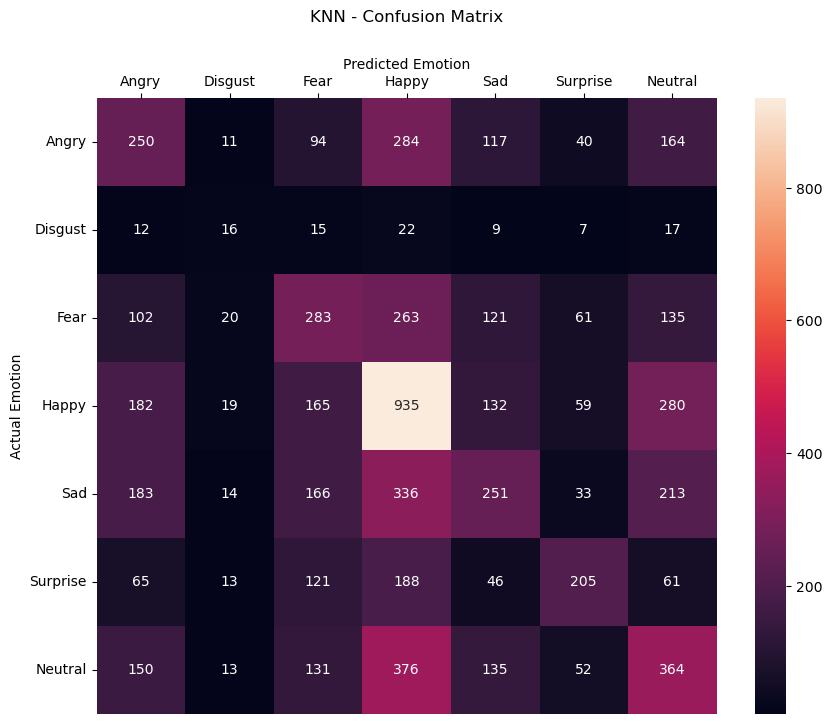

In [35]:
from sklearn.metrics import confusion_matrix

cm_knn = confusion_matrix(y_test, y_pred)

emotion_names = [
    "Angry", "Disgust", "Fear",
    "Happy", "Sad", "Surprise", "Neutral"
]

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    xticklabels=emotion_names,
    yticklabels=emotion_names
)

plt.tick_params(
    axis="x",
    top=True,
    labeltop=True,
    bottom=False,
    labelbottom=False
)

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.xlabel("Predicted Emotion")
plt.gca().xaxis.set_label_position("top")

plt.ylabel("Actual Emotion")

plt.title(
    "KNN - Confusion Matrix",
    pad=55
)

plt.show()

Observation: KNN classified the seven emotion classes with moderate performance. The confusion matrix shows that some visually similar emotions were frequently misclassified.

Gaussian Naive Bayes

### Gaussian Naive Bayes — Conditional Independence Assumption

Gaussian Naive Bayes assumes that the input features are conditionally independent given the target class.

This means that once the emotion class is known, the model assumes that each feature contributes independently to the prediction.

For example, if the emotion is "Happy", Gaussian Naive Bayes assumes that the values of the different features can be treated as independent when calculating the probability of the Happy class.

This assumption is called "naive" because it is a strong simplification. In image data, pixels and extracted features can be related to each other, so they may not actually be independent.

In this project, PCA was applied before classification. PCA transforms the original pixel features into principal components and reduces correlation between the components. This can make the independence assumption more reasonable, although the components are not guaranteed to be completely independent.

Therefore, Gaussian Naive Bayes is simple and computationally efficient, but its performance can be affected when the input features have strong dependencies.

In [36]:
from sklearn.naive_bayes import GaussianNB

# Create Gaussian Naive Bayes model
gnb_model = GaussianNB()

# Train the model
gnb_model.fit(X_train_pca, y_train)

# Make predictions
y_pred_gnb = gnb_model.predict(X_test_pca)

print("Gaussian Naive Bayes training completed!")
print("Predictions:", y_pred_gnb[:10])

Gaussian Naive Bayes training completed!
Predictions: [5 6 1 0 3 6 2 2 2 4]


In [37]:
from sklearn.metrics import accuracy_score, f1_score

gnb_accuracy = accuracy_score(y_test, y_pred_gnb)

gnb_f1 = f1_score(
    y_test,
    y_pred_gnb,
    average="weighted"
)

print("Gaussian Naive Bayes Accuracy:", gnb_accuracy)
print("Gaussian Naive Bayes Weighted F1:", gnb_f1)

Gaussian Naive Bayes Accuracy: 0.31842446977348143
Gaussian Naive Bayes Weighted F1: 0.301252878009798


In [38]:
from sklearn.metrics import classification_report

print("Gaussian Naive Bayes - Classification Report\n")

print(
    classification_report(
        y_test,
        y_pred_gnb,
        target_names=[
            "Angry",
            "Disgust",
            "Fear",
            "Happy",
            "Sad",
            "Surprise",
            "Neutral"
        ]
    )
)

Gaussian Naive Bayes - Classification Report

              precision    recall  f1-score   support

       Angry       0.24      0.14      0.18       960
     Disgust       0.05      0.09      0.07        98
        Fear       0.19      0.20      0.20       985
       Happy       0.38      0.62      0.47      1772
         Sad       0.30      0.18      0.22      1196
    Surprise       0.44      0.32      0.37       699
     Neutral       0.32      0.27      0.30      1221

    accuracy                           0.32      6931
   macro avg       0.28      0.26      0.26      6931
weighted avg       0.31      0.32      0.30      6931



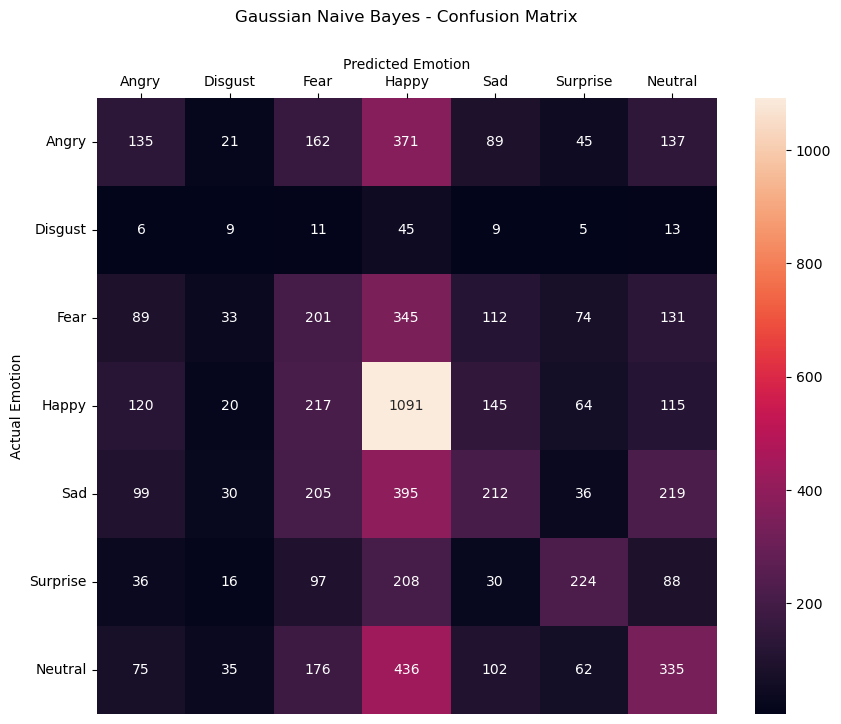

In [39]:
from sklearn.metrics import confusion_matrix

cm_gnb = confusion_matrix(y_test, y_pred_gnb)

emotion_names = [
    "Angry", "Disgust", "Fear",
    "Happy", "Sad", "Surprise", "Neutral"
]

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_gnb,
    annot=True,
    fmt="d",
    xticklabels=emotion_names,
    yticklabels=emotion_names
)

plt.tick_params(
    axis="x",
    top=True,
    labeltop=True,
    bottom=False,
    labelbottom=False
)

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.xlabel("Predicted Emotion")
plt.gca().xaxis.set_label_position("top")

plt.ylabel("Actual Emotion")

plt.title(
    "Gaussian Naive Bayes - Confusion Matrix",
    pad=55
)

plt.show()

Observation: Gaussian Naive Bayes showed lower classification performance compared with Logistic Regression. Several emotion classes were confused, mainly because the model assumes conditional independence between features.

Decision Tree Classifier

In [40]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

depths = [5, 10, 15, 20]

dt_results = []

for depth in depths:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train_pca, y_train)

    predictions = model.predict(X_test_pca)

    accuracy = accuracy_score(y_test, predictions)

    dt_results.append({
        "max_depth": depth,
        "Accuracy": accuracy
    })

dt_tuning = pd.DataFrame(dt_results)

print("Decision Tree max_depth tuning results:")
print(dt_tuning)

Decision Tree max_depth tuning results:
   max_depth  Accuracy
0          5  0.296061
1         10  0.288270
2         15  0.271678
3         20  0.271678


In [41]:
depths = [5, 10, 15, 20]

dt_results = []

for depth in depths:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train_pca, y_train)

    predictions = model.predict(X_test_pca)

    accuracy = accuracy_score(y_test, predictions)

    dt_results.append({
        "max_depth": depth,
        "Accuracy": accuracy
    })

dt_tuning = pd.DataFrame(dt_results)

print("Decision Tree max_depth tuning results:")
print(dt_tuning)

Decision Tree max_depth tuning results:
   max_depth  Accuracy
0          5  0.296061
1         10  0.288270
2         15  0.271678
3         20  0.271678


In [42]:
best_depth = int(
    dt_tuning.loc[
        dt_tuning["Accuracy"].idxmax(),
        "max_depth"
    ]
)

print("Best max_depth:", best_depth)

Best max_depth: 5


In [43]:
dt_model = DecisionTreeClassifier(
    max_depth=best_depth,
    random_state=42
)

dt_model.fit(X_train_pca, y_train)

y_pred_dt = dt_model.predict(X_test_pca)

print("Final Decision Tree training completed!")
print("Predictions:", y_pred_dt[:10])

Final Decision Tree training completed!
Predictions: [5 3 4 3 6 2 3 5 3 3]


In [44]:
from sklearn.metrics import accuracy_score, f1_score

dt_accuracy = accuracy_score(y_test, y_pred_dt)

dt_f1 = f1_score(
    y_test,
    y_pred_dt,
    average="weighted"
)

print("Decision Tree Accuracy:", dt_accuracy)
print("Decision Tree Weighted F1:", dt_f1)

Decision Tree Accuracy: 0.29606117443370367
Decision Tree Weighted F1: 0.24626374306376658


In [45]:
from sklearn.metrics import classification_report

print("Decision Tree - Classification Report\n")

print(
    classification_report(
        y_test,
        y_pred_dt,
        target_names=[
            "Angry",
            "Disgust",
            "Fear",
            "Happy",
            "Sad",
            "Surprise",
            "Neutral"
        ],
        zero_division=0
    )
)

Decision Tree - Classification Report

              precision    recall  f1-score   support

       Angry       0.20      0.00      0.01       960
     Disgust       0.00      0.00      0.00        98
        Fear       0.20      0.14      0.17       985
       Happy       0.34      0.69      0.45      1772
         Sad       0.26      0.14      0.18      1196
    Surprise       0.30      0.27      0.28       699
     Neutral       0.25      0.27      0.26      1221

    accuracy                           0.30      6931
   macro avg       0.22      0.22      0.19      6931
weighted avg       0.26      0.30      0.25      6931



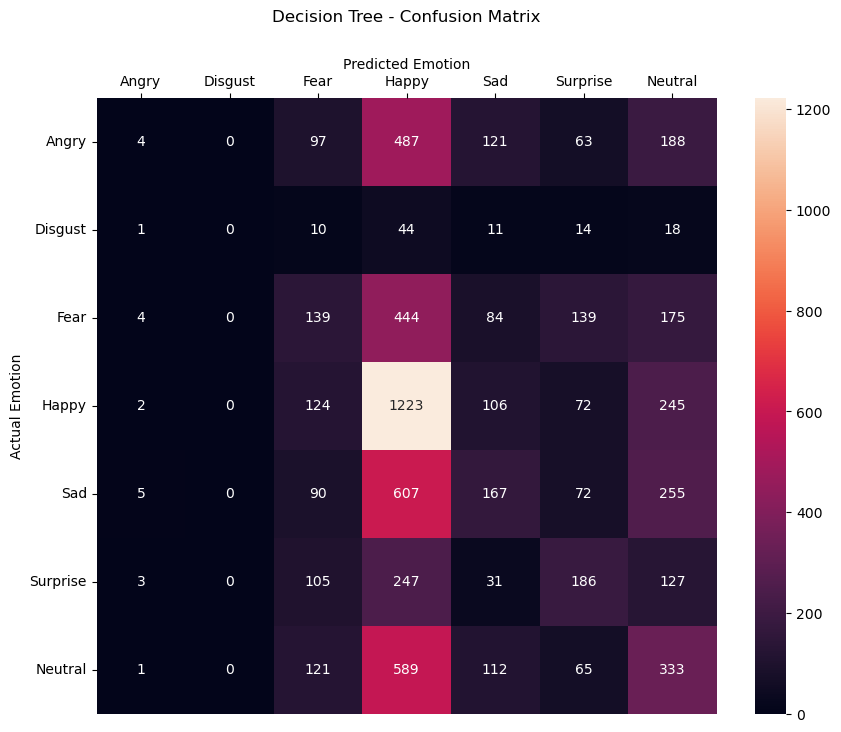

In [46]:
from sklearn.metrics import confusion_matrix

cm_dt = confusion_matrix(y_test, y_pred_dt)

emotion_names = [
    "Angry", "Disgust", "Fear",
    "Happy", "Sad", "Surprise", "Neutral"
]

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    xticklabels=emotion_names,
    yticklabels=emotion_names
)

plt.tick_params(
    axis="x",
    top=True,
    labeltop=True,
    bottom=False,
    labelbottom=False
)

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.xlabel("Predicted Emotion")
plt.gca().xaxis.set_label_position("top")

plt.ylabel("Actual Emotion")

plt.title(
    "Decision Tree - Confusion Matrix",
    pad=55
)

plt.show()

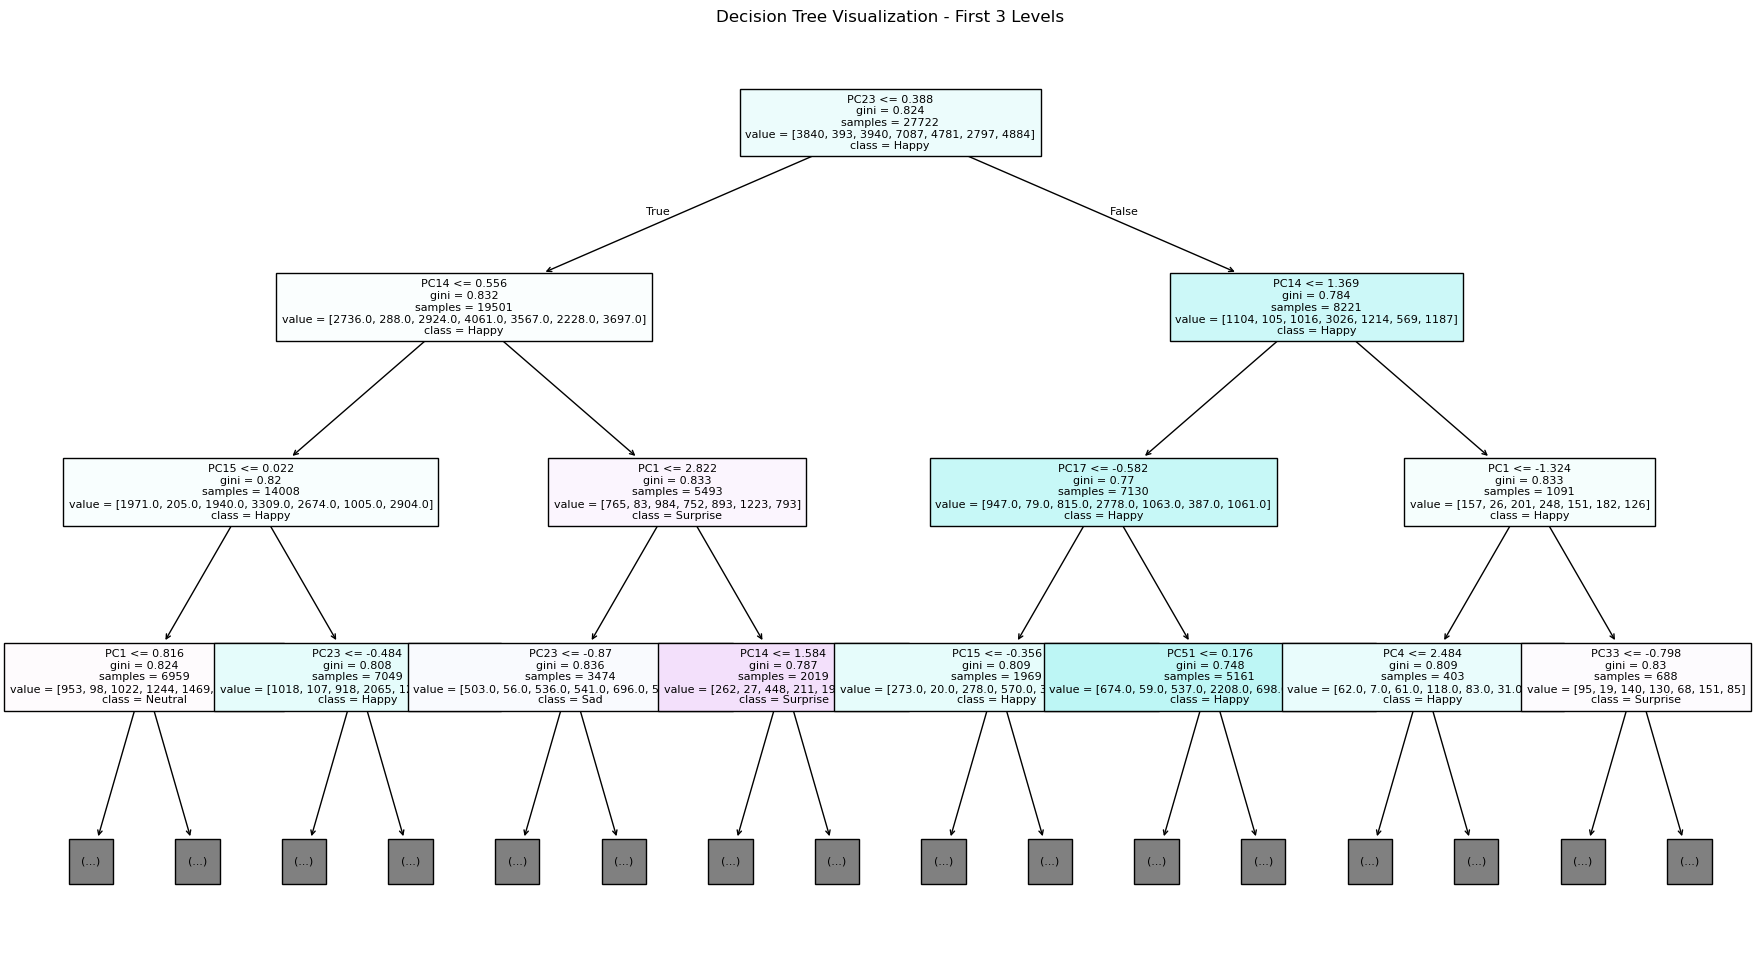

In [47]:
plt.figure(figsize=(22, 12))

plot_tree(
    dt_model,
    max_depth=3,
    filled=True,
    feature_names=[
        f"PC{i+1}" for i in range(X_train_pca.shape[1])
    ],
    class_names=emotion_names,
    fontsize=8
)

plt.title(
    "Decision Tree Visualization - First 3 Levels"
)

plt.show()

Observation: The Decision Tree classifier was able to classify the seven emotion classes using the reduced PCA features. The confusion matrix shows which emotions are correctly classified and which emotions are frequently confused with each other.

SVC (Support Vector Classifier)

In [48]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Use a smaller subset because SVC is computationally expensive
X_train_svc = X_train_pca[:8000]
y_train_svc = y_train[:8000]

results = []

for kernel in ["linear", "rbf"]:
    
    for C in [0.1, 1.0]:
        
        print("Training:", kernel, "C =", C)
        
        model = SVC(
            C=C,
            kernel=kernel,
            random_state=42
        )
        
        model.fit(X_train_svc, y_train_svc)
        
        pred = model.predict(X_test_pca)
        
        accuracy = accuracy_score(y_test, pred)
        
        results.append({
            "Kernel": kernel,
            "C": C,
            "Accuracy": accuracy
        })

results_df = pd.DataFrame(results)

results_df

Training: linear C = 0.1
Training: linear C = 1.0
Training: rbf C = 0.1
Training: rbf C = 1.0


,Kernel,C,Accuracy
0,linear,0.1,0.361853
1,linear,1.0,0.362141
2,rbf,0.1,0.278459
3,rbf,1.0,0.381619


In [49]:
best_svc = results_df.loc[results_df["Accuracy"].idxmax()]

print("Best Kernel:", best_svc["Kernel"])
print("Best C:", best_svc["C"])
print("Best Accuracy:", best_svc["Accuracy"])

Best Kernel: rbf
Best C: 1.0
Best Accuracy: 0.38161881402395037


In [50]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

best_kernel = best_svc["Kernel"]
best_C = float(best_svc["C"])

svc_model = SVC(
    C=best_C,
    kernel=best_kernel,
    random_state=42
)

svc_model.fit(X_train_svc, y_train_svc)

y_pred_svc = svc_model.predict(X_test_pca)

svc_accuracy = accuracy_score(y_test, y_pred_svc)
svc_f1 = f1_score(y_test, y_pred_svc, average="weighted")

print("SVC training completed!")
print("SVC Accuracy:", svc_accuracy)
print("SVC Weighted F1:", svc_f1)

SVC training completed!
SVC Accuracy: 0.38161881402395037
SVC Weighted F1: 0.3475393821752044


In [51]:
from sklearn.metrics import classification_report

print("SVC - Classification Report\n")

print(classification_report(
    y_test,
    y_pred_svc,
    target_names=emotion_names,
    zero_division=0
))

SVC - Classification Report

              precision    recall  f1-score   support

       Angry       0.29      0.11      0.16       960
     Disgust       0.00      0.00      0.00        98
        Fear       0.30      0.11      0.16       985
       Happy       0.42      0.71      0.53      1772
         Sad       0.32      0.39      0.35      1196
    Surprise       0.48      0.37      0.42       699
     Neutral       0.36      0.37      0.37      1221

    accuracy                           0.38      6931
   macro avg       0.31      0.29      0.28      6931
weighted avg       0.36      0.38      0.35      6931



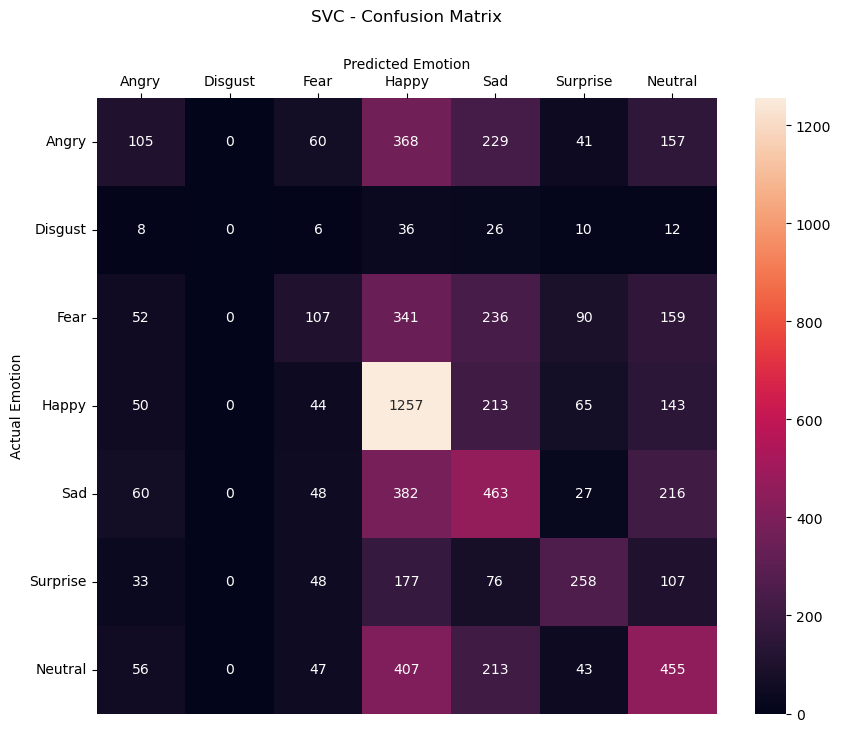

In [52]:
from sklearn.metrics import confusion_matrix

cm_svc = confusion_matrix(y_test, y_pred_svc)

emotion_names = [
    "Angry", "Disgust", "Fear",
    "Happy", "Sad", "Surprise", "Neutral"
]

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_svc,
    annot=True,
    fmt="d",
    xticklabels=emotion_names,
    yticklabels=emotion_names
)

plt.tick_params(
    axis="x",
    top=True,
    labeltop=True,
    bottom=False,
    labelbottom=False
)

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.xlabel("Predicted Emotion")
plt.gca().xaxis.set_label_position("top")

plt.ylabel("Actual Emotion")

plt.title(
    "SVC - Confusion Matrix",
    pad=55
)

plt.show()

Observation: SVC was able to classify the seven emotion classes using the PCA-reduced features. The confusion matrix shows that some visually similar emotions are more difficult to distinguish, resulting in misclassifications between certain classes.

In [53]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Gaussian Naive Bayes",
        "Decision Tree",
        "SVC"
    ],
    "Accuracy": [
        lr_accuracy,
        knn_accuracy,
        gnb_accuracy,
        dt_accuracy,
        svc_accuracy
    ],
    "Weighted F1": [
        lr_f1,
        knn_f1,
        gnb_f1,
        dt_f1,
        svc_f1
    ]
})

comparison

,Model,Accuracy,Weighted F1
0,Logistic Regression,0.365171,0.333871
1,KNN,0.332420,0.325285
2,Gaussian Naive Bayes,0.318424,0.301253
3,Decision Tree,0.296061,0.246264
4,SVC,0.381619,0.347539


## Model Comparison

- **Higher Accuracy** → more correct predictions overall.
- **Higher Weighted F1** → better balance between precision and recall, considering class imbalance.
- We consider **both metrics** for model comparison.

**Observation:** SVC achieved the highest Accuracy (**38.16%**) and Weighted F1 (**34.75%**) among the tested models.

# Part B — Ensemble & Neural Network Classifiers

Part B trains the five remaining classification algorithms on **exactly the same data as Part A**:

- same FER2013 dataset after the same cleaning (missing-value check, 1,234 duplicates removed),
- same stratified 80/20 train–test split (`random_state=42`),
- same 0–1 pixel scaling and the same **100-component PCA** features (`X_train_pca`, `X_test_pca`).

| # | Algorithm | Hyperparameters tuned |
|---|-----------|-----------------------|
| 6 | Random Forest Classifier | `n_estimators` (+ feature importance) |
| 7 | AdaBoost Classifier | `n_estimators`, `learning_rate` |
| 8 | Gradient Boosting Classifier (sklearn `HistGradientBoostingClassifier`) | `learning_rate`, `max_iter` (number of boosting rounds) |
| 9 | Bagging Classifier (Decision Tree base estimator) | `n_estimators` |
| 10 | MLP Classifier (Neural Network) | `hidden_layer_sizes`, `activation` |

**Evaluation metrics (all mandatory):** Accuracy, Precision, Recall, F1-score (weighted), Confusion Matrix and ROC-AUC. Because this is a 7-class problem, ROC-AUC is calculated with the **One-vs-Rest (OvR)** strategy (weighted by class support, consistent with the other weighted metrics).

**Tuning protocol:** hyperparameters are chosen on a **validation set** (20 % of the training data). The best setting is then refit on the full training set and evaluated once on the untouched test set, so the test set is never used to pick hyperparameters.

### B.0 Setup — common imports, validation split and evaluation helper

In [54]:
import time
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, auc
)
from sklearn.preprocessing import label_binarize

class_names = ["Angry", "Disgust", "Fear", "Happy", "Sad", "Surprise", "Neutral"]
class_ids = list(range(7))

# Validation split carved out of the TRAINING data only (used for tuning)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_pca, y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Tuning-train  :", X_tr.shape)
print("Validation    :", X_val.shape)
print("Full training :", X_train_pca.shape)
print("Test          :", X_test_pca.shape)

# Dictionary that will hold the final test-set metrics of every model (Part A + Part B)
all_results = {}


def get_metrics(y_true, y_pred, y_proba):
    """Accuracy, weighted Precision / Recall / F1 and OvR ROC-AUC."""
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "F1-score": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "ROC-AUC (OvR)": roc_auc_score(
            y_true, y_proba, multi_class="ovr", average="weighted", labels=class_ids
        ),
    }


def plot_confusion(y_true, y_pred, title):
    """Confusion matrix in the same style as Part A."""
    cm = confusion_matrix(y_true, y_pred, labels=class_ids)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt="d",
                xticklabels=class_names, yticklabels=class_names)
    plt.tick_params(axis="x", top=True, labeltop=True, bottom=False, labelbottom=False)
    plt.xticks(rotation=0)
    plt.yticks(rotation=0)
    plt.xlabel("Predicted Emotion")
    plt.gca().xaxis.set_label_position("top")
    plt.ylabel("Actual Emotion")
    plt.title(f"{title} - Confusion Matrix", pad=55)
    plt.show()


def evaluate_model(name, model, X_eval=None, y_eval=None, show=True):
    """Predict on the test set, print all metrics, report and confusion matrix."""
    X_eval = X_test_pca if X_eval is None else X_eval
    y_eval = y_test if y_eval is None else y_eval

    y_pred = model.predict(X_eval)
    y_proba = model.predict_proba(X_eval)
    metrics = get_metrics(y_eval, y_pred, y_proba)

    if show:
        print(f"===== {name} — Test-set performance =====")
        for k, v in metrics.items():
            print(f"{k:<15}: {v:.4f}")
        print(f"\n{name} - Classification Report\n")
        print(classification_report(y_eval, y_pred, labels=class_ids,
                                    target_names=class_names, zero_division=0))
        plot_confusion(y_eval, y_pred, name)

    return metrics, y_pred, y_proba

Tuning-train  : (22177, 100)
Validation    : (5545, 100)
Full training : (27722, 100)
Test          : (6931, 100)


## 6. Random Forest Classifier

Random Forest builds many decision trees on bootstrap samples of the training data and, at each split, considers only a random subset of features. The final class is decided by majority vote. Averaging many de-correlated trees reduces the high variance seen with the single Decision Tree in Part A.

**Tuning:** `n_estimators` (number of trees) = 100, 200, 300.

In [55]:
from sklearn.ensemble import RandomForestClassifier

rf_results = []

for n in [100, 200, 300]:
    start = time.time()
    model = RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1)
    model.fit(X_tr, y_tr)
    pred = model.predict(X_val)
    rf_results.append({
        "n_estimators": n,
        "Val Accuracy": accuracy_score(y_val, pred),
        "Val Weighted F1": f1_score(y_val, pred, average="weighted"),
        "Time (s)": round(time.time() - start, 1)
    })
    print("Trained Random Forest with n_estimators =", n)

rf_tuning = pd.DataFrame(rf_results)
rf_tuning

Trained Random Forest with n_estimators = 100
Trained Random Forest with n_estimators = 200
Trained Random Forest with n_estimators = 300


,n_estimators,Val Accuracy,Val Weighted F1,Time (s)
0,100,0.395131,0.362468,39.5
1,200,0.404509,0.366903,56.5
2,300,0.408476,0.367217,85.0


Best n_estimators: 300


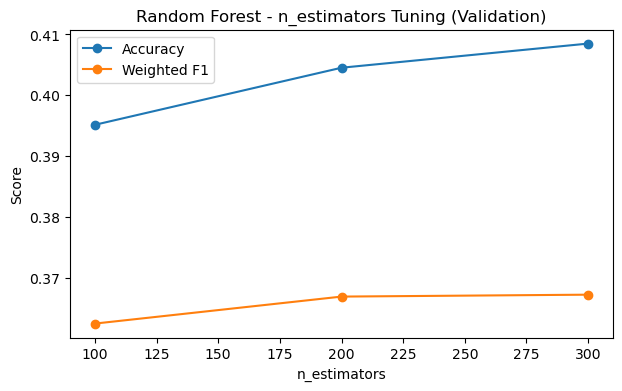

In [56]:
best_rf_n = int(rf_tuning.loc[rf_tuning["Val Weighted F1"].idxmax(), "n_estimators"])
print("Best n_estimators:", best_rf_n)

plt.figure(figsize=(7, 4))
plt.plot(rf_tuning["n_estimators"], rf_tuning["Val Accuracy"], marker="o", label="Accuracy")
plt.plot(rf_tuning["n_estimators"], rf_tuning["Val Weighted F1"], marker="o", label="Weighted F1")
plt.title("Random Forest - n_estimators Tuning (Validation)")
plt.xlabel("n_estimators")
plt.ylabel("Score")
plt.legend()
plt.show()

===== Random Forest — Test-set performance =====
Accuracy       : 0.4063
Precision      : 0.4650
Recall         : 0.4063
F1-score       : 0.3680
ROC-AUC (OvR)  : 0.7317

Random Forest - Classification Report

              precision    recall  f1-score   support

       Angry       0.60      0.10      0.18       960
     Disgust       0.93      0.13      0.23        98
        Fear       0.50      0.18      0.27       985
       Happy       0.37      0.84      0.51      1772
         Sad       0.37      0.31      0.34      1196
    Surprise       0.67      0.43      0.52       699
     Neutral       0.41      0.29      0.34      1221

    accuracy                           0.41      6931
   macro avg       0.55      0.33      0.34      6931
weighted avg       0.46      0.41      0.37      6931



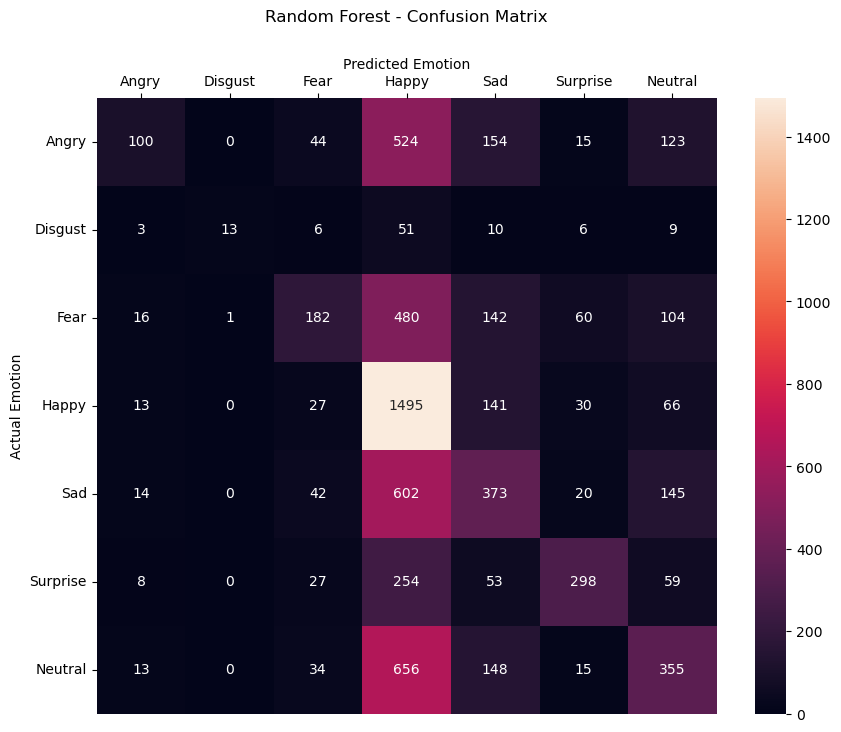

In [57]:
rf_model = RandomForestClassifier(n_estimators=best_rf_n, random_state=42, n_jobs=-1)
rf_model.fit(X_train_pca, y_train)

rf_metrics, y_pred_rf, y_proba_rf = evaluate_model("Random Forest", rf_model)
all_results["Random Forest"] = rf_metrics

### Random Forest — Feature Importance

Feature importance (mean decrease in impurity) shows which PCA components the forest relied on most when splitting. As in Part A, the features are principal components, not individual pixels.

Top 10 most important PCA components:
Feature  Importance
   PC23    0.019791
   PC14    0.017599
    PC1    0.016169
   PC15    0.013420
    PC4    0.012284
    PC9    0.012237
   PC12    0.012089
   PC30    0.011859
   PC33    0.011850
    PC2    0.011818


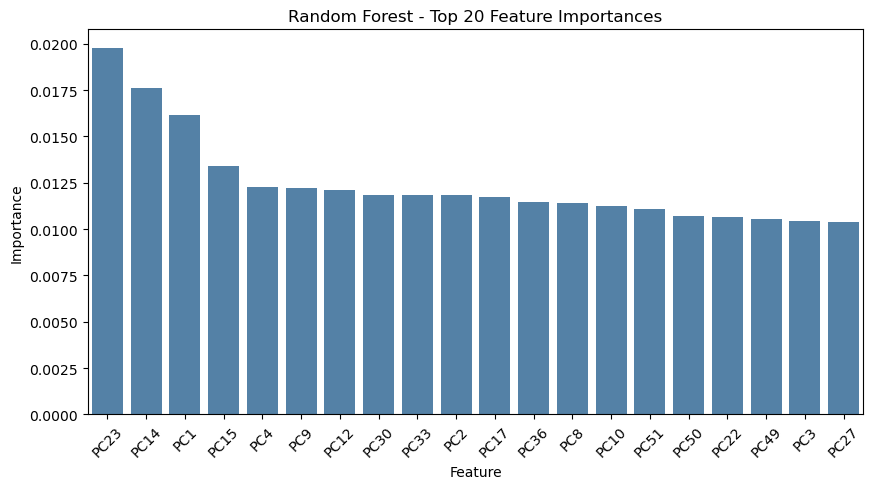


Share of total importance held by the first 10 PCs: 0.115


In [58]:
rf_importance = pd.DataFrame({
    "Feature": [f"PC{i+1}" for i in range(X_train_pca.shape[1])],
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

print("Top 10 most important PCA components:")
print(rf_importance.head(10).to_string(index=False))

plt.figure(figsize=(10, 5))
sns.barplot(data=rf_importance.head(20), x="Feature", y="Importance", color="steelblue")
plt.title("Random Forest - Top 20 Feature Importances")
plt.xticks(rotation=45)
plt.show()

print("\nShare of total importance held by the first 10 PCs:",
      round(rf_model.feature_importances_[:10].sum(), 3))

**Observation:** Random Forest combines hundreds of trees, so it is far more stable than the single depth-limited Decision Tree from Part A and gives a clear improvement over it. The feature-importance plot shows that the earliest principal components (which capture the most variance in the faces — overall lighting, face shape, mouth/eye regions) carry the most importance, while later components contribute progressively less. Visually similar emotions (Fear / Sad / Neutral / Angry) are still frequently confused, and the small Disgust class remains the hardest.

## 7. AdaBoost Classifier

AdaBoost trains weak learners sequentially. After each round, the weights of misclassified samples are increased so that the next learner focuses on the hard examples. A shallow decision tree (`max_depth=2`) is used as the weak learner (the default 1-level stump is too weak for 7 classes).

**Tuning:** `n_estimators` = 100, 200 and `learning_rate` = 0.5, 1.0.

In [59]:
from sklearn.ensemble import AdaBoostClassifier

ada_results = []

for n in [100, 200]:
    for lr in [0.5, 1.0]:
        start = time.time()
        model = AdaBoostClassifier(
            estimator=DecisionTreeClassifier(max_depth=2, random_state=42),
            n_estimators=n,
            learning_rate=lr,
            random_state=42
        )
        model.fit(X_tr, y_tr)
        pred = model.predict(X_val)
        ada_results.append({
            "n_estimators": n,
            "learning_rate": lr,
            "Val Accuracy": accuracy_score(y_val, pred),
            "Val Weighted F1": f1_score(y_val, pred, average="weighted"),
            "Time (s)": round(time.time() - start, 1)
        })
        print(f"Trained AdaBoost: n_estimators={n}, learning_rate={lr}")

ada_tuning = pd.DataFrame(ada_results)
ada_tuning

Trained AdaBoost: n_estimators=100, learning_rate=0.5
Trained AdaBoost: n_estimators=100, learning_rate=1.0
Trained AdaBoost: n_estimators=200, learning_rate=0.5
Trained AdaBoost: n_estimators=200, learning_rate=1.0


,n_estimators,learning_rate,Val Accuracy,Val Weighted F1,Time (s)
0,100,0.5,0.315059,0.281082,122.5
1,100,1.0,0.306041,0.284602,125.0
2,200,0.5,0.320469,0.289450,285.6
3,200,1.0,0.310189,0.289951,257.4


Best n_estimators : 200
Best learning_rate: 1.0


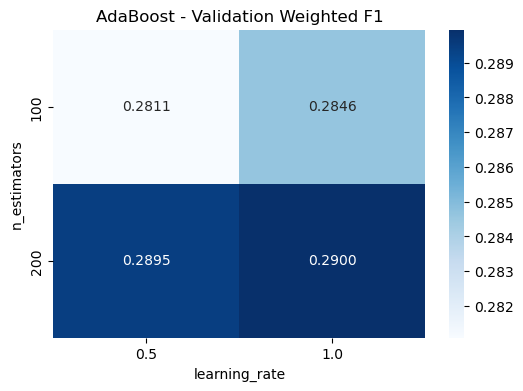

In [60]:
best_ada = ada_tuning.loc[ada_tuning["Val Weighted F1"].idxmax()]
best_ada_n = int(best_ada["n_estimators"])
best_ada_lr = float(best_ada["learning_rate"])
print("Best n_estimators :", best_ada_n)
print("Best learning_rate:", best_ada_lr)

plt.figure(figsize=(6, 4))
sns.heatmap(ada_tuning.pivot(index="n_estimators", columns="learning_rate",
                             values="Val Weighted F1"),
            annot=True, fmt=".4f", cmap="Blues")
plt.title("AdaBoost - Validation Weighted F1")
plt.show()

===== AdaBoost — Test-set performance =====
Accuracy       : 0.3124
Precision      : 0.2899
Recall         : 0.3124
F1-score       : 0.2886
ROC-AUC (OvR)  : 0.6404

AdaBoost - Classification Report

              precision    recall  f1-score   support

       Angry       0.22      0.08      0.12       960
     Disgust       0.00      0.00      0.00        98
        Fear       0.22      0.16      0.19       985
       Happy       0.37      0.60      0.46      1772
         Sad       0.27      0.26      0.26      1196
    Surprise       0.39      0.28      0.33       699
     Neutral       0.27      0.30      0.28      1221

    accuracy                           0.31      6931
   macro avg       0.25      0.24      0.23      6931
weighted avg       0.29      0.31      0.29      6931



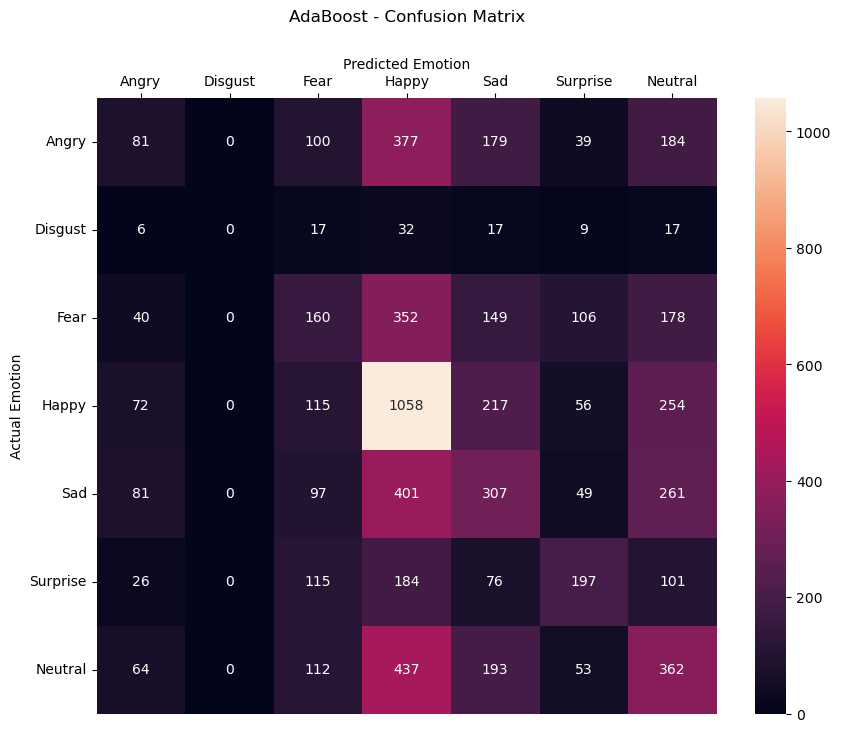

In [61]:
ada_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=2, random_state=42),
    n_estimators=best_ada_n,
    learning_rate=best_ada_lr,
    random_state=42
)
ada_model.fit(X_train_pca, y_train)

ada_metrics, y_pred_ada, y_proba_ada = evaluate_model("AdaBoost", ada_model)
all_results["AdaBoost"] = ada_metrics

**Observation:** AdaBoost improves on a single shallow tree by repeatedly re-weighting hard samples, but because each weak learner is very simple and boosting is sensitive to noisy / mislabeled images (FER2013 has many ambiguous faces), its gain is limited. The learning rate and number of estimators trade off against each other: a smaller learning rate needs more rounds to reach the same fit.

## 8. Gradient Boosting Classifier

Gradient Boosting also builds trees sequentially, but each new tree is fitted to the **gradient of the loss** (the remaining errors) of the current ensemble. scikit-learn's `HistGradientBoostingClassifier` is used — it is sklearn's histogram-based GBM (the same idea as LightGBM) and is much faster than the classic `GradientBoostingClassifier` on 27,000+ samples × 7 classes.

**Tuning:** `learning_rate` = 0.05, 0.1 and `max_iter` (number of boosting rounds / estimators) = 200, 300.

In [62]:
from sklearn.ensemble import HistGradientBoostingClassifier

gb_results = []

for lr in [0.05, 0.1]:
    for n_iter in [200, 300]:
        start = time.time()
        model = HistGradientBoostingClassifier(
            learning_rate=lr,
            max_iter=n_iter,
            early_stopping=False,
            random_state=42
        )
        model.fit(X_tr, y_tr)
        pred = model.predict(X_val)
        gb_results.append({
            "learning_rate": lr,
            "max_iter": n_iter,
            "Val Accuracy": accuracy_score(y_val, pred),
            "Val Weighted F1": f1_score(y_val, pred, average="weighted"),
            "Time (s)": round(time.time() - start, 1)
        })
        print(f"Trained Gradient Boosting: learning_rate={lr}, max_iter={n_iter}")

gb_tuning = pd.DataFrame(gb_results)
gb_tuning

Trained Gradient Boosting: learning_rate=0.05, max_iter=200
Trained Gradient Boosting: learning_rate=0.05, max_iter=300
Trained Gradient Boosting: learning_rate=0.1, max_iter=200
Trained Gradient Boosting: learning_rate=0.1, max_iter=300


,learning_rate,max_iter,Val Accuracy,Val Weighted F1,Time (s)
0,0.05,200,0.412444,0.389875,50.3
1,0.05,300,0.417674,0.397634,72.7
2,0.10,200,0.406673,0.389692,47.6
3,0.10,300,0.407935,0.392076,71.8


Best learning_rate: 0.05
Best max_iter     : 300


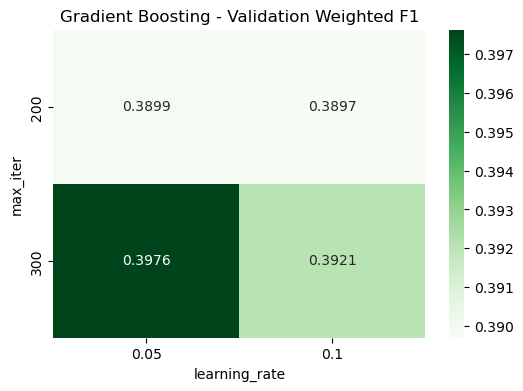

In [63]:
best_gb = gb_tuning.loc[gb_tuning["Val Weighted F1"].idxmax()]
best_gb_lr = float(best_gb["learning_rate"])
best_gb_iter = int(best_gb["max_iter"])
print("Best learning_rate:", best_gb_lr)
print("Best max_iter     :", best_gb_iter)

plt.figure(figsize=(6, 4))
sns.heatmap(gb_tuning.pivot(index="max_iter", columns="learning_rate",
                            values="Val Weighted F1"),
            annot=True, fmt=".4f", cmap="Greens")
plt.title("Gradient Boosting - Validation Weighted F1")
plt.show()

===== Gradient Boosting — Test-set performance =====
Accuracy       : 0.4171
Precision      : 0.4167
Recall         : 0.4171
F1-score       : 0.3970
ROC-AUC (OvR)  : 0.7402

Gradient Boosting - Classification Report

              precision    recall  f1-score   support

       Angry       0.38      0.18      0.24       960
     Disgust       0.91      0.10      0.18        98
        Fear       0.38      0.22      0.28       985
       Happy       0.46      0.71      0.55      1772
         Sad       0.32      0.35      0.33      1196
    Surprise       0.56      0.47      0.51       699
     Neutral       0.39      0.40      0.39      1221

    accuracy                           0.42      6931
   macro avg       0.49      0.35      0.36      6931
weighted avg       0.42      0.42      0.40      6931



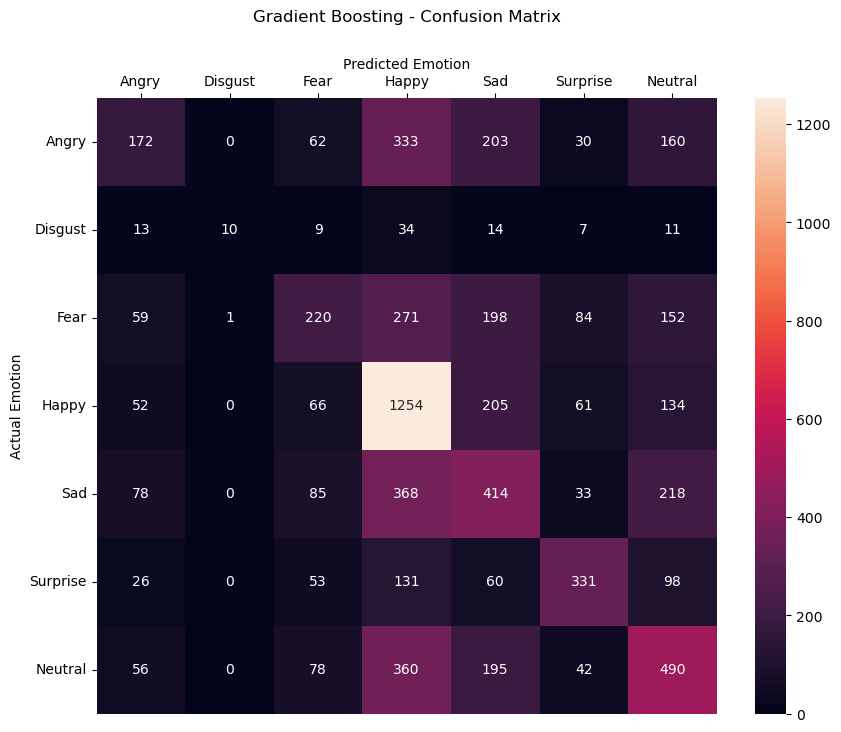

In [64]:
gb_model = HistGradientBoostingClassifier(
    learning_rate=best_gb_lr,
    max_iter=best_gb_iter,
    early_stopping=False,
    random_state=42
)
gb_model.fit(X_train_pca, y_train)

gb_metrics, y_pred_gb, y_proba_gb = evaluate_model("Gradient Boosting", gb_model)
all_results["Gradient Boosting"] = gb_metrics

**Observation:** Gradient Boosting corrects the residual errors of the previous trees step by step, which lets it model non-linear interactions between PCA components better than a single tree or AdaBoost. It is usually one of the strongest tree-based models on this data. Happy and Surprise (the most distinctive expressions) are recognised best, while Fear, Sad and Angry are still mixed up with each other.

## 9. Bagging Classifier (Decision Tree base estimator)

Bagging (Bootstrap Aggregating) trains many full Decision Trees, each on a different bootstrap sample of the training set, and combines them by voting. Unlike Random Forest, every tree may use **all** features at every split, so the trees are more correlated. Bagging mainly reduces the variance of the unstable Decision Tree.

**Tuning:** `n_estimators` = 10, 30, 50.

In [65]:
from sklearn.ensemble import BaggingClassifier

bag_results = []

for n in [10, 30, 50]:
    start = time.time()
    model = BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=n,
        random_state=42,
        n_jobs=-1
    )
    model.fit(X_tr, y_tr)
    pred = model.predict(X_val)
    bag_results.append({
        "n_estimators": n,
        "Val Accuracy": accuracy_score(y_val, pred),
        "Val Weighted F1": f1_score(y_val, pred, average="weighted"),
        "Time (s)": round(time.time() - start, 1)
    })
    print("Trained Bagging with n_estimators =", n)

bag_tuning = pd.DataFrame(bag_results)
bag_tuning

Trained Bagging with n_estimators = 10
Trained Bagging with n_estimators = 30
Trained Bagging with n_estimators = 50


,n_estimators,Val Accuracy,Val Weighted F1,Time (s)
0,10,0.312894,0.305757,38.3
1,30,0.367719,0.350238,77.9
2,50,0.384310,0.363363,123.5


Best n_estimators: 50


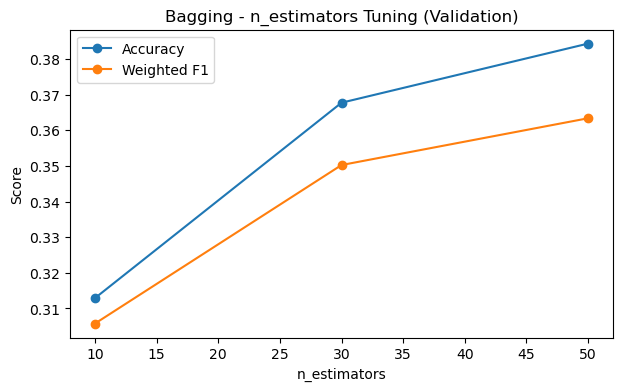

In [66]:
best_bag_n = int(bag_tuning.loc[bag_tuning["Val Weighted F1"].idxmax(), "n_estimators"])
print("Best n_estimators:", best_bag_n)

plt.figure(figsize=(7, 4))
plt.plot(bag_tuning["n_estimators"], bag_tuning["Val Accuracy"], marker="o", label="Accuracy")
plt.plot(bag_tuning["n_estimators"], bag_tuning["Val Weighted F1"], marker="o", label="Weighted F1")
plt.title("Bagging - n_estimators Tuning (Validation)")
plt.xlabel("n_estimators")
plt.ylabel("Score")
plt.legend()
plt.show()

===== Bagging (Decision Tree) — Test-set performance =====
Accuracy       : 0.3809
Precision      : 0.3807
Recall         : 0.3809
F1-score       : 0.3585
ROC-AUC (OvR)  : 0.6872

Bagging (Decision Tree) - Classification Report

              precision    recall  f1-score   support

       Angry       0.30      0.16      0.21       960
     Disgust       0.93      0.14      0.25        98
        Fear       0.38      0.23      0.28       985
       Happy       0.40      0.70      0.51      1772
         Sad       0.31      0.29      0.30      1196
    Surprise       0.53      0.42      0.47       699
     Neutral       0.36      0.30      0.33      1221

    accuracy                           0.38      6931
   macro avg       0.46      0.32      0.33      6931
weighted avg       0.38      0.38      0.36      6931



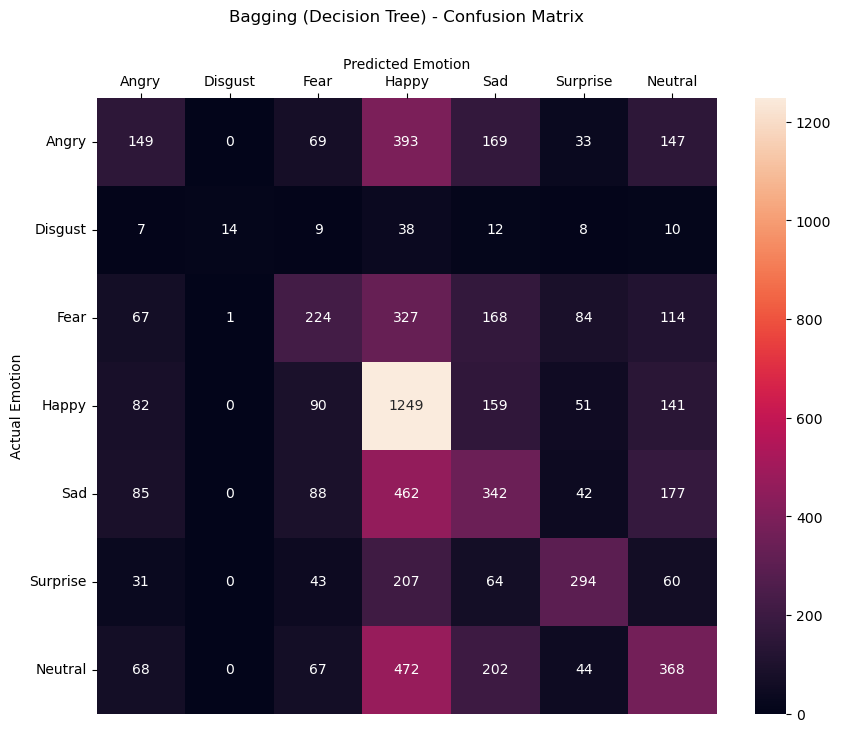

In [67]:
bag_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=best_bag_n,
    random_state=42,
    n_jobs=-1
)
bag_model.fit(X_train_pca, y_train)

bag_metrics, y_pred_bag, y_proba_bag = evaluate_model("Bagging (Decision Tree)", bag_model)
all_results["Bagging (Decision Tree)"] = bag_metrics

**Observation:** Bagging clearly outperforms the single Decision Tree from Part A, confirming that much of the tree's error was variance. Adding more trees helps up to a point and then the gain flattens. Because all trees can use the same strong PCA components, the trees are correlated, so Bagging usually stays slightly below Random Forest.

## 10. MLP Classifier (Neural Network)

A Multi-Layer Perceptron is a feed-forward neural network with one or more hidden layers trained by back-propagation. It can learn non-linear combinations of the PCA features. The PCA components have very different variances, so they are standardised with `StandardScaler` inside a pipeline (fitted on training data only). `early_stopping=True` holds out 10 % of the training data internally to stop training when validation score stops improving, which limits over-fitting.

**Tuning:** `hidden_layer_sizes` = (128,), (256, 128) and `activation` = relu, tanh.

In [68]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def build_mlp(hidden_layers, activation):
    return make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=hidden_layers,
            activation=activation,
            alpha=1e-3,
            max_iter=300,
            early_stopping=True,
            random_state=42
        )
    )


mlp_results = []

for hidden in [(128,), (256, 128)]:
    for act in ["relu", "tanh"]:
        start = time.time()
        model = build_mlp(hidden, act)
        model.fit(X_tr, y_tr)
        pred = model.predict(X_val)
        mlp_results.append({
            "hidden_layer_sizes": str(hidden),
            "activation": act,
            "Val Accuracy": accuracy_score(y_val, pred),
            "Val Weighted F1": f1_score(y_val, pred, average="weighted"),
            "Time (s)": round(time.time() - start, 1)
        })
        print(f"Trained MLP: hidden_layer_sizes={hidden}, activation={act}")

mlp_tuning = pd.DataFrame(mlp_results)
mlp_tuning

Trained MLP: hidden_layer_sizes=(128,), activation=relu
Trained MLP: hidden_layer_sizes=(128,), activation=tanh
Trained MLP: hidden_layer_sizes=(256, 128), activation=relu
Trained MLP: hidden_layer_sizes=(256, 128), activation=tanh


,hidden_layer_sizes,activation,Val Accuracy,Val Weighted F1,Time (s)
0,"(128,)",relu,0.397295,0.381491,5.7
1,"(128,)",tanh,0.362669,0.347181,9.5
2,"(256, 128)",relu,0.405951,0.394241,13.2
3,"(256, 128)",tanh,0.380703,0.363068,14.5


Best hidden_layer_sizes: (256, 128)
Best activation        : relu


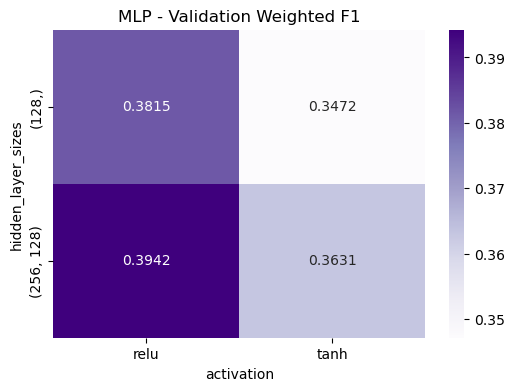

In [69]:
import ast

best_mlp = mlp_tuning.loc[mlp_tuning["Val Weighted F1"].idxmax()]
best_mlp_hidden = ast.literal_eval(best_mlp["hidden_layer_sizes"])
best_mlp_act = best_mlp["activation"]
print("Best hidden_layer_sizes:", best_mlp_hidden)
print("Best activation        :", best_mlp_act)

plt.figure(figsize=(6, 4))
sns.heatmap(mlp_tuning.pivot(index="hidden_layer_sizes", columns="activation",
                             values="Val Weighted F1"),
            annot=True, fmt=".4f", cmap="Purples")
plt.title("MLP - Validation Weighted F1")
plt.show()

===== MLP (Neural Network) — Test-set performance =====
Accuracy       : 0.4057
Precision      : 0.3875
Recall         : 0.4057
F1-score       : 0.3920
ROC-AUC (OvR)  : 0.7296

MLP (Neural Network) - Classification Report

              precision    recall  f1-score   support

       Angry       0.27      0.23      0.25       960
     Disgust       0.28      0.11      0.16        98
        Fear       0.30      0.28      0.29       985
       Happy       0.52      0.70      0.60      1772
         Sad       0.32      0.26      0.29      1196
    Surprise       0.49      0.49      0.49       699
     Neutral       0.37      0.34      0.36      1221

    accuracy                           0.41      6931
   macro avg       0.36      0.34      0.35      6931
weighted avg       0.39      0.41      0.39      6931



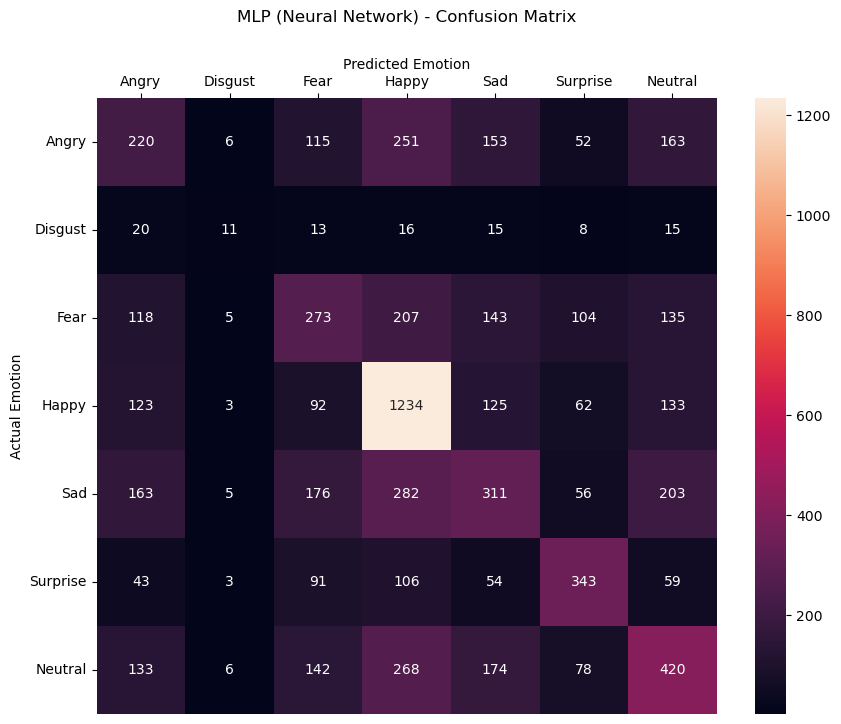

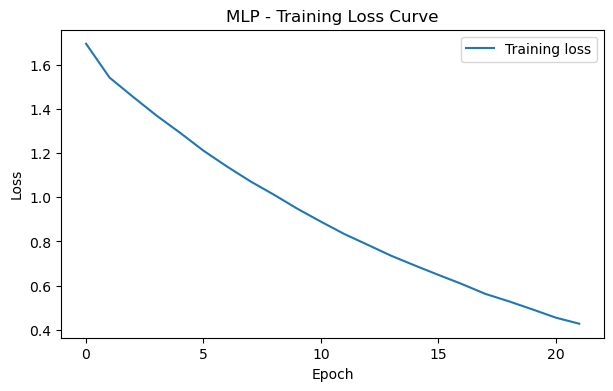

Epochs trained (early stopping): 22


In [70]:
mlp_model = build_mlp(best_mlp_hidden, best_mlp_act)
mlp_model.fit(X_train_pca, y_train)

mlp_metrics, y_pred_mlp, y_proba_mlp = evaluate_model("MLP (Neural Network)", mlp_model)
all_results["MLP (Neural Network)"] = mlp_metrics

# Training loss curve of the final network
mlp_net = mlp_model.named_steps["mlpclassifier"]
plt.figure(figsize=(7, 4))
plt.plot(mlp_net.loss_curve_, label="Training loss")
plt.title("MLP - Training Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()
print("Epochs trained (early stopping):", mlp_net.n_iter_)

**Observation:** The MLP learns non-linear combinations of the PCA features and is typically among the best models on this data, together with SVC and Gradient Boosting. The loss curve decreases smoothly and early stopping halts training once the internal validation score stops improving, which prevents the network from memorising the noisy FER2013 labels. Like the other models, it struggles most with Disgust (very few samples) and with Fear vs Sad.

# Full Comparison — All 10 Classification Algorithms

To compare all models on the **same metrics**, the Part A models are re-evaluated on the same test set with Precision, Recall and ROC-AUC added (Part A only reported Accuracy and F1).

- Logistic Regression, KNN, Gaussian Naive Bayes and Decision Tree already provide `predict_proba`.
- The Part A SVC was trained without probability estimates, so for ROC-AUC an identical SVC (same kernel, C and 8,000-sample training subset) is refit with `probability=True`. Its class predictions (and therefore Accuracy / Precision / Recall / F1) are taken from the original Part A SVC.

In [71]:
start = time.time()

# --- Part A models (already trained above) ---
part_a_models = {
    "Logistic Regression": logistic_model,
    "KNN": knn_model,
    "Gaussian Naive Bayes": gnb_model,
    "Decision Tree": dt_model,
}

part_a_results = {}
for name, model in part_a_models.items():
    m, _, _ = evaluate_model(name, model, show=False)
    part_a_results[name] = m

# --- SVC: predictions from the Part A model, probabilities from a probability-enabled twin ---
svc_proba_model = SVC(C=best_C, kernel=best_kernel, probability=True, random_state=42)
svc_proba_model.fit(X_train_svc, y_train_svc)

part_a_results["SVC"] = get_metrics(
    y_test,
    svc_model.predict(X_test_pca),
    svc_proba_model.predict_proba(X_test_pca)
)

print("Part A models re-evaluated in", round(time.time() - start, 1), "seconds")

Part A models re-evaluated in 129.2 seconds


In [72]:
model_part = {name: "A" for name in part_a_results}
model_part.update({name: "B" for name in all_results})

final_comparison = pd.DataFrame({**part_a_results, **all_results}).T
final_comparison.insert(0, "Part", pd.Series(model_part))
final_comparison = final_comparison.sort_values(
    ["F1-score", "ROC-AUC (OvR)"], ascending=False
)
final_comparison.index.name = "Model"
final_comparison.insert(0, "Rank", range(1, len(final_comparison) + 1))

print("FINAL COMPARISON — ALL 10 CLASSIFICATION ALGORITHMS (test set, weighted averages)")
final_comparison.style.format({
    "Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}",
    "F1-score": "{:.4f}", "ROC-AUC (OvR)": "{:.4f}"
}).background_gradient(
    subset=["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC (OvR)"], cmap="Greens"
)

FINAL COMPARISON — ALL 10 CLASSIFICATION ALGORITHMS (test set, weighted averages)


,Rank,Part,Accuracy,Precision,Recall,F1-score,ROC-AUC (OvR)
Model,,,,,,,
Gradient Boosting,1,B,0.4171,0.4167,0.4171,0.3970,0.7402
MLP (Neural Network),2,B,0.4057,0.3875,0.4057,0.3920,0.7296
Random Forest,3,B,0.4063,0.4650,0.4063,0.3680,0.7317
Bagging (Decision Tree),4,B,0.3809,0.3807,0.3809,0.3585,0.6872
SVC,5,A,0.3816,0.3582,0.3816,0.3475,0.7116
Logistic Regression,6,A,0.3652,0.3361,0.3652,0.3339,0.6907
KNN,7,A,0.3324,0.3301,0.3324,0.3253,0.6492
Gaussian Naive Bayes,8,A,0.3184,0.3109,0.3184,0.3013,0.6439
AdaBoost,9,B,0.3124,0.2899,0.3124,0.2886,0.6404


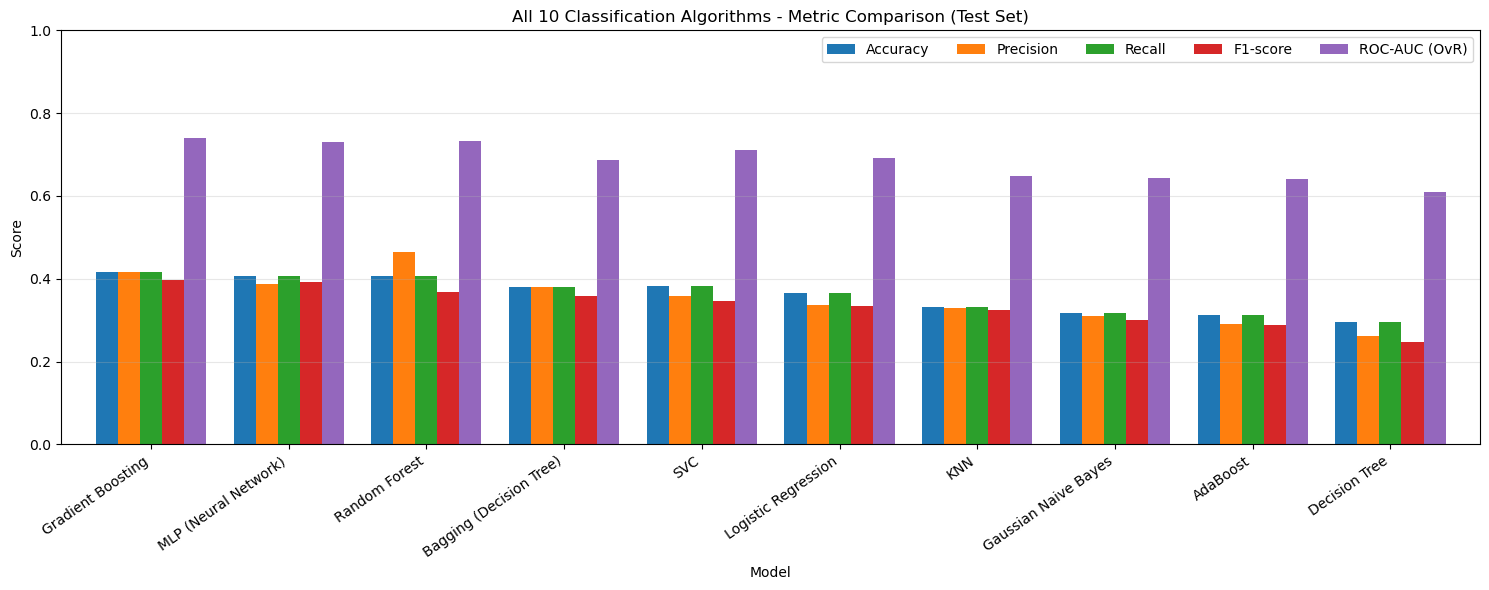

In [73]:
metric_cols = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC (OvR)"]

final_comparison[metric_cols].plot(kind="bar", figsize=(15, 6), width=0.8)
plt.title("All 10 Classification Algorithms - Metric Comparison (Test Set)")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 1)
plt.legend(loc="upper right", ncol=5)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Reading the comparison table

- **Accuracy** – share of all test images classified correctly.
- **Precision (weighted)** – of the images predicted as an emotion, how many were really that emotion (averaged over classes, weighted by class size).
- **Recall (weighted)** – of the images of each emotion, how many were found.
- **F1-score (weighted)** – harmonic mean of precision and recall; the main ranking metric because the classes are imbalanced (Happy ≈ 25 %, Disgust ≈ 1.5 %).
- **ROC-AUC (OvR)** – how well the predicted probabilities rank each emotion against all the others, independent of a decision threshold (0.5 = random, 1.0 = perfect).

Models are ranked by weighted F1, with ROC-AUC as the tie-breaker. In general the ensemble and neural-network models of Part B outperform the simple Part A models (Naive Bayes, Decision Tree, KNN), because they can model non-linear relationships between PCA components while controlling variance.

# Final Model Selection

**Selection criterion:** the model with the highest **weighted F1-score** on the test set is chosen (ROC-AUC as tie-breaker), because:

1. the dataset is imbalanced, so accuracy alone over-rewards predicting the majority class (Happy);
2. weighted F1 balances precision and recall across all seven emotions;
3. ROC-AUC confirms that the model's probability estimates are also well-ranked.

The best model is then given an additional, wider **hyperparameter search** (`RandomizedSearchCV`, 3-fold stratified cross-validation on the training set, scoring = weighted F1), and the tuned version is compared with the **default-hyperparameter** version of the same algorithm to document the improvement.

In [74]:
best_model_name = final_comparison.index[0]
runner_up_name = final_comparison.index[1]
best_row = final_comparison.loc[best_model_name]
runner_row = final_comparison.loc[runner_up_name]

print("BEST MODEL:", best_model_name, f"(Part {best_row['Part']})")
print("-" * 60)
for col in metric_cols:
    print(f"{col:<15}: {best_row[col]:.4f}   (runner-up {runner_up_name}: {runner_row[col]:.4f})")

print("\nJustification:")
print(f"- Highest weighted F1 of all 10 models ({best_row['F1-score']:.4f}), "
      f"{(best_row['F1-score'] - runner_row['F1-score']) * 100:.2f} points above the runner-up.")
print(f"- ROC-AUC (OvR) of {best_row['ROC-AUC (OvR)']:.4f}, rank "
      f"{int(final_comparison['ROC-AUC (OvR)'].rank(ascending=False)[best_model_name])} of 10 on probability ranking.")
print(f"- Accuracy of {best_row['Accuracy']:.4f} vs. "
      f"{final_comparison['Accuracy'].min():.4f} for the weakest model.")

BEST MODEL: Gradient Boosting (Part B)
------------------------------------------------------------
Accuracy       : 0.4171   (runner-up MLP (Neural Network): 0.4057)
Precision      : 0.4167   (runner-up MLP (Neural Network): 0.3875)
Recall         : 0.4171   (runner-up MLP (Neural Network): 0.4057)
F1-score       : 0.3970   (runner-up MLP (Neural Network): 0.3920)
ROC-AUC (OvR)  : 0.7402   (runner-up MLP (Neural Network): 0.7296)

Justification:
- Highest weighted F1 of all 10 models (0.3970), 0.50 points above the runner-up.
- ROC-AUC (OvR) of 0.7402, rank 1 of 10 on probability ranking.
- Accuracy of 0.4171 vs. 0.2961 for the weakest model.


### Hyperparameter tuning of the selected model

A search space is defined for every algorithm, so the cell below automatically tunes **whichever model was selected** above. For SVC the same 8,000-sample subset as Part A is used to keep training time reasonable.

In [75]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.base import clone

# (default model, search space, training data) for every algorithm
search_spaces = {
    "Logistic Regression": (
        LogisticRegression(max_iter=1000, random_state=42),
        {"C": [0.01, 0.05, 0.1, 0.5, 1.0, 5.0]},
        (X_train_pca, y_train)),
    "KNN": (
        KNeighborsClassifier(n_jobs=-1),
        {"n_neighbors": [5, 9, 15, 21, 31], "weights": ["uniform", "distance"], "p": [1, 2]},
        (X_train_pca, y_train)),
    "Gaussian Naive Bayes": (
        GaussianNB(),
        {"var_smoothing": [1e-11, 1e-9, 1e-7, 1e-5, 1e-3, 1e-2]},
        (X_train_pca, y_train)),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=42),
        {"max_depth": [5, 8, 10, 12], "min_samples_leaf": [1, 10, 20, 50],
         "criterion": ["gini", "entropy"]},
        (X_train_pca, y_train)),
    "SVC": (
        SVC(probability=True, random_state=42),
        {"C": [1, 3, 5, 10], "gamma": ["scale", 0.005, 0.01, 0.02], "kernel": ["rbf"]},
        (X_train_svc, y_train_svc)),
    "Random Forest": (
        RandomForestClassifier(random_state=42, n_jobs=-1),
        {"n_estimators": [200, 300, 400], "max_features": ["sqrt", 0.2],
         "min_samples_leaf": [1, 2, 4], "max_depth": [None, 25]},
        (X_train_pca, y_train)),
    "AdaBoost": (
        AdaBoostClassifier(random_state=42),
        {"estimator": [DecisionTreeClassifier(max_depth=d, random_state=42) for d in [2, 3]],
         "n_estimators": [200, 300], "learning_rate": [0.3, 0.5, 1.0]},
        (X_train_pca, y_train)),
    "Gradient Boosting": (
        HistGradientBoostingClassifier(random_state=42),
        {"learning_rate": [0.05, 0.1], "max_iter": [300, 500],
         "max_leaf_nodes": [15, 31, 63], "l2_regularization": [0.0, 1.0]},
        (X_train_pca, y_train)),
    "Bagging (Decision Tree)": (
        BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42),
                          random_state=42, n_jobs=-1),
        {"n_estimators": [50, 100], "max_samples": [0.7, 1.0], "max_features": [0.5, 0.7, 1.0]},
        (X_train_pca, y_train)),
    "MLP (Neural Network)": (
        make_pipeline(StandardScaler(),
                      MLPClassifier(max_iter=300, early_stopping=True, random_state=42)),
        {"mlpclassifier__hidden_layer_sizes": [(256,), (256, 128), (512, 256)],
         "mlpclassifier__activation": ["relu", "tanh"],
         "mlpclassifier__alpha": [1e-4, 1e-3, 1e-2],
         "mlpclassifier__learning_rate_init": [1e-3, 5e-4]},
        (X_train_pca, y_train)),
}

base_estimator, param_space, (X_fit, y_fit) = search_spaces[best_model_name]
print("Tuning:", best_model_name)
print("Search space:", {k: v for k, v in param_space.items() if k != "estimator"})

Tuning: Gradient Boosting
Search space: {'learning_rate': [0.05, 0.1], 'max_iter': [300, 500], 'max_leaf_nodes': [15, 31, 63], 'l2_regularization': [0.0, 1.0]}


In [76]:
# 1) Baseline: selected algorithm with DEFAULT hyperparameters
start = time.time()
default_model = clone(base_estimator)
default_model.fit(X_fit, y_fit)
default_metrics, _, _ = evaluate_model(f"{best_model_name} (default)", default_model, show=False)
print("Default model trained in", round(time.time() - start, 1), "s")

# 2) RandomizedSearchCV with 3-fold stratified CV on the training data
start = time.time()
search = RandomizedSearchCV(
    estimator=clone(base_estimator),
    param_distributions=param_space,
    n_iter=8,
    scoring="f1_weighted",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=-1,
    refit=True,
    verbose=1
)
search.fit(X_fit, y_fit)
print("Search finished in", round(time.time() - start, 1), "s")
print("Best CV weighted F1:", round(search.best_score_, 4))
print("Best hyperparameters:", search.best_params_)

cv_table = pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]]
cv_table.sort_values("rank_test_score")

Default model trained in 30.5 s
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Search finished in 490.5 s
Best CV weighted F1: 0.3781
Best hyperparameters: {'max_leaf_nodes': 31, 'max_iter': 500, 'learning_rate': 0.05, 'l2_regularization': 1.0}


,params,mean_test_score,std_test_score,rank_test_score
1,"{'max_leaf_nodes': 31, 'max_iter': 500, 'learn...",0.378054,0.002675,1
6,"{'max_leaf_nodes': 31, 'max_iter': 300, 'learn...",0.378054,0.002675,1
7,"{'max_leaf_nodes': 31, 'max_iter': 300, 'learn...",0.374194,0.003385,3
0,"{'max_leaf_nodes': 63, 'max_iter': 300, 'learn...",0.371881,0.003511,4
4,"{'max_leaf_nodes': 63, 'max_iter': 500, 'learn...",0.371881,0.003511,4
2,"{'max_leaf_nodes': 15, 'max_iter': 300, 'learn...",0.369154,0.004792,6
3,"{'max_leaf_nodes': 15, 'max_iter': 300, 'learn...",0.367306,0.003200,7
5,"{'max_leaf_nodes': 15, 'max_iter': 500, 'learn...",0.365791,0.003145,8


In [77]:
tuned_model = search.best_estimator_
tuned_metrics, _, _ = evaluate_model(f"{best_model_name} (tuned)", tuned_model, show=False)
section_metrics = final_comparison.loc[best_model_name, metric_cols].astype(float).to_dict()

improvement_table = pd.DataFrame({
    "Default hyperparameters": default_metrics,
    "Earlier tuned version": section_metrics,
    "RandomizedSearchCV tuned": tuned_metrics,
}).T[metric_cols]

delta = improvement_table.loc["RandomizedSearchCV tuned"] - improvement_table.loc["Default hyperparameters"]
improvement_table.loc["Improvement vs default (pts)"] = delta * 100

print(f"{best_model_name} — effect of hyperparameter tuning (test set)")
improvement_table.style.format("{:.4f}")

Gradient Boosting — effect of hyperparameter tuning (test set)


,Accuracy,Precision,Recall,F1-score,ROC-AUC (OvR)
Default hyperparameters,0.4001,0.3904,0.4001,0.3788,0.7216
Earlier tuned version,0.4171,0.4167,0.4171,0.3970,0.7402
RandomizedSearchCV tuned,0.4168,0.4138,0.4168,0.3956,0.7371
Improvement vs default (pts),1.6736,2.3371,1.6736,1.6828,1.5532


Metrics improved by tuning: ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC (OvR)']
  Accuracy       : 0.4001 -> 0.4168 (+1.67 pts)
  Precision      : 0.3904 -> 0.4138 (+2.34 pts)
  Recall         : 0.4001 -> 0.4168 (+1.67 pts)
  F1-score       : 0.3788 -> 0.3956 (+1.68 pts)
  ROC-AUC (OvR)  : 0.7216 -> 0.7371 (+1.55 pts)

FINAL MODEL: Gradient Boosting — RandomizedSearchCV tuned


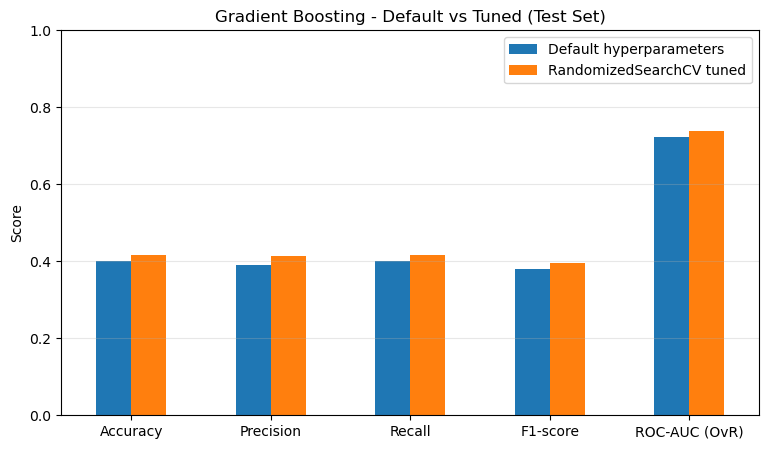

In [78]:
# Pick the final model = best of the candidates on weighted F1
candidates = {
    "Default hyperparameters": (default_model, default_metrics),
    "RandomizedSearchCV tuned": (tuned_model, tuned_metrics),
}
final_version = max(candidates, key=lambda k: candidates[k][1]["F1-score"])
final_model, final_metrics = candidates[final_version]

improved = [m for m in metric_cols if tuned_metrics[m] > default_metrics[m]]
print("Metrics improved by tuning:", improved if improved else "none")
for m in improved:
    print(f"  {m:<15}: {default_metrics[m]:.4f} -> {tuned_metrics[m]:.4f} "
          f"(+{(tuned_metrics[m] - default_metrics[m]) * 100:.2f} pts)")

print(f"\nFINAL MODEL: {best_model_name} — {final_version}")

improvement_table.loc[["Default hyperparameters", "RandomizedSearchCV tuned"]].T.plot(
    kind="bar", figsize=(9, 5))
plt.title(f"{best_model_name} - Default vs Tuned (Test Set)")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.show()

### Final model — full evaluation (confusion matrix and One-vs-Rest ROC curves)

===== FINAL: Gradient Boosting — Test-set performance =====
Accuracy       : 0.4168
Precision      : 0.4138
Recall         : 0.4168
F1-score       : 0.3956
ROC-AUC (OvR)  : 0.7371

FINAL: Gradient Boosting - Classification Report

              precision    recall  f1-score   support

       Angry       0.37      0.18      0.24       960
     Disgust       0.92      0.11      0.20        98
        Fear       0.36      0.21      0.26       985
       Happy       0.46      0.72      0.56      1772
         Sad       0.32      0.36      0.34      1196
    Surprise       0.54      0.44      0.49       699
     Neutral       0.40      0.41      0.40      1221

    accuracy                           0.42      6931
   macro avg       0.48      0.35      0.36      6931
weighted avg       0.41      0.42      0.40      6931



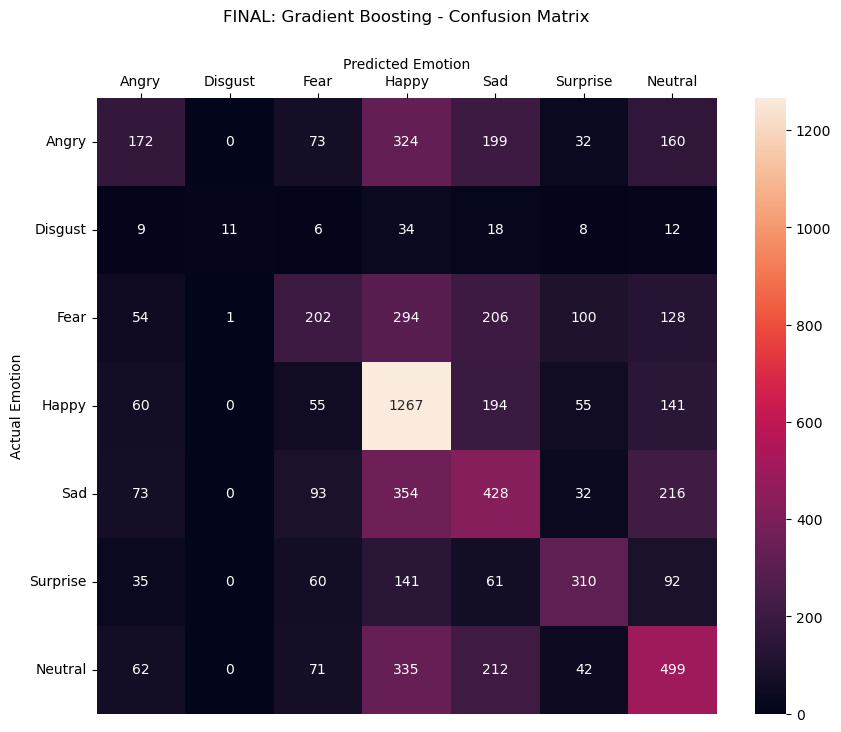

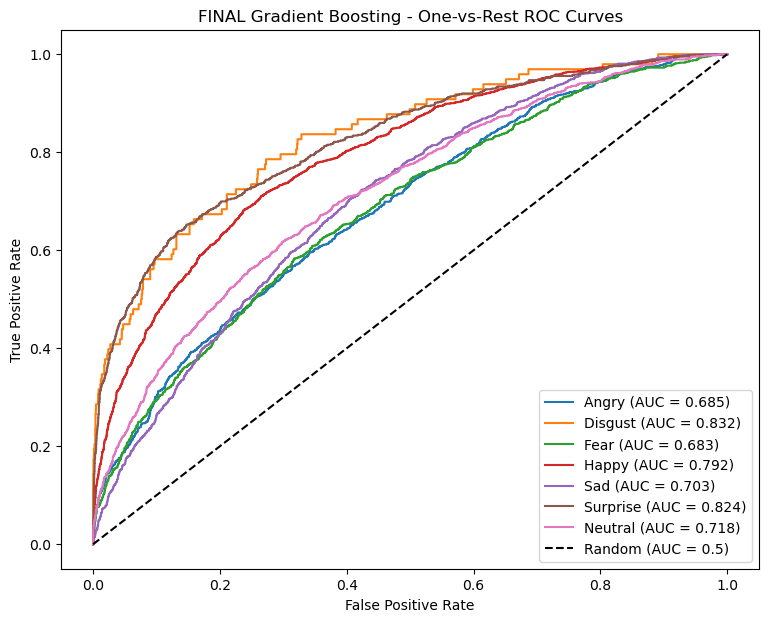

In [79]:
final_metrics, y_pred_final, y_proba_final = evaluate_model(
    f"FINAL: {best_model_name}", final_model
)

# One-vs-Rest ROC curve for each emotion
y_test_bin = label_binarize(y_test, classes=class_ids)

plt.figure(figsize=(9, 7))
for i, name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba_final[:, i])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random (AUC = 0.5)")
plt.title(f"FINAL {best_model_name} - One-vs-Rest ROC Curves")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.show()

In [80]:
import os

os.makedirs("../models", exist_ok=True)
joblib.dump(
    {"pca": pca, "model": final_model, "class_names": class_names,
     "note": "Input: 48x48 grayscale pixels flattened, divided by 255, then pca.transform"},
    "../models/final_emotion_classifier.pkl"
)
print("Final model saved to ../models/final_emotion_classifier.pkl")

Final model saved to ../models/final_emotion_classifier.pkl


## Conclusion

- All five Part B algorithms (Random Forest, AdaBoost, Gradient Boosting, Bagging, MLP) were trained on the **same cleaned FER2013 data, train–test split and PCA features** as Part A, each with hyperparameter tuning on a validation set and full evaluation (Accuracy, weighted Precision / Recall / F1, confusion matrix, OvR ROC-AUC).
- A single comparison table ranks all **10 algorithms** on the same five metrics.
- The best model was selected by weighted F1 (with ROC-AUC as tie-breaker) and further tuned with `RandomizedSearchCV`; the improvement over its default configuration is documented in the improvement table above.
- Overall accuracy on FER2013 stays well below 50 % for classical ML models on PCA features, because many expressions (Fear / Sad / Angry / Neutral) look alike in 48×48 grayscale images and the Disgust class has very few samples. Convolutional neural networks that learn spatial features directly from the pixels would be the natural next step to go beyond this level.